# Etapa 8 · Quantização: a rede em inteiros de 8 bits

| | |
|---|---|
| **Pergunta** | Quanto custa, em qualidade, passar a rede para inteiros de 8 bits, e quanto se ganha em tamanho e latência? |
| **Entrada** | `entregas/07_poda/decisao.json` (os modelos podados que seguem, de cada modelo de partida, e onde estão), `entregas/06_destilacao/` e `entregas/04b_intencao/` (os mesmos modelos sem poda), `entregas/01_dados/` (os pedidos) e o que os comandos de `especialista/experimentos/etapa8.py` gravaram. |
| **Entrega** | `entregas/08_quantizacao/`: cada modelo exportado e quantizado (3 sementes), a comparação pareada de cada forma de quantizar com o mesmo modelo em 32 bits, tamanho e latência medidos, e o `decisao.json` com o modelo final do projeto. |
| **Pronto quando** | (1) cada modelo que a Etapa 7 marcou foi quantizado nas 3 sementes, sem nenhum treino; (2) o ONNX de 32 bits dá as mesmas respostas do PyTorch em todos os pedidos de `dev` e do teste; (3) os pesos podados continuam em zero depois de quantizar; (4) cada forma tem comparação pareada, com intervalo de 95%, contra o mesmo modelo em 32 bits, em `dev` e no teste; (5) o tamanho foi medido em arquivos gravados e a latência no protocolo da régua, com a máquina quieta; (6) a forma final saiu de `dev`, pela regra escrita antes, e o treino ciente de quantização só entra se a regra mandar; (7) os sistemas entregues reproduzem as respostas do teste. |

**O que é quantizar.** A rede guarda cada peso como um número real de 32 bits. Quantizar é guardar o mesmo peso como um inteiro de 8 bits, que só tem 256 valores possíveis, mais dois números por tensor que dizem como voltar ao número real. O arquivo fica perto de 4 vezes menor, e a conta com inteiros pode ser mais rápida. O preço é um erro de arredondamento em cada peso. Esta etapa mede esse preço.

**Artigos de apoio**

- O esquema de quantização (escala e ponto zero) e a conta só com inteiros: Jacob et al., *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference* ([arXiv 1712.05877](https://arxiv.org/abs/1712.05877)).
- Um Transformer em 8 bits, o que quantizar e o que deixar em 32 bits: Zafrir et al., *Q8BERT: Quantized 8Bit BERT* ([arXiv 1910.06188](https://arxiv.org/abs/1910.06188)).
- Quantização pós-treino, só dos pesos ou também das ativações, e quando o treino é necessário: Krishnamoorthi, *Quantizing deep convolutional networks for efficient inference: A whitepaper* ([arXiv 1806.08342](https://arxiv.org/abs/1806.08342)); Nagel et al., *A White Paper on Neural Network Quantization* ([arXiv 2106.08295](https://arxiv.org/abs/2106.08295)).
- As formas de quantizar, lado a lado (dinâmica, estática, com treino): Gholami et al., *A Survey of Quantization Methods for Efficient Neural Network Inference* ([arXiv 2103.13630](https://arxiv.org/abs/2103.13630)).
- Por que as ativações de um Transformer são difíceis de quantizar com faixa fixa: Bondarenko et al., *Understanding and Overcoming the Challenges of Efficient Transformer Quantization* ([arXiv 2109.12948](https://arxiv.org/abs/2109.12948)).
- Um Transformer quantizado em 8 bits depois de treinado, com menos de 0,5% de perda: Bhandare et al., *Efficient 8-Bit Quantization of Transformer Neural Machine Language Translation Model* ([arXiv 1906.00532](https://arxiv.org/abs/1906.00532)).
- Podar, quantizar e, por fim, codificar o arquivo: Han et al., *Deep Compression* ([arXiv 1510.00149](https://arxiv.org/abs/1510.00149)).
- Quantização e poda juntas podem derrubar o modelo (lá, com 4 bits e modelos gerativos): Nema et al., *Compression Technique Interactions in Small Language Models: A Factorial Ablation Study* ([arXiv 2611.00464](https://arxiv.org/abs/2611.00464)).

**Roteiro**

1. Os modelos que chegam da poda
2. O que ficou decidido antes de medir
3. A exportação: a mesma rede, fora do PyTorch
4. O que a quantização faz com os pesos
5. Qualidade: cada forma contra o mesmo modelo em 32 bits
6. Tamanho
7. Latência
8. A forma final de cada modelo
9. Entrega
10. Resposta

In [1]:
import json
import shutil
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import ouro
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.compressao import exportacao, quantizacao
from especialista.compressao.exportacao import SistemaOnnx
from especialista.dados import massive
from especialista.experimentos import etapa8
from especialista.modelos.diet import SistemaDiet

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PASTA = entrega("08_quantizacao")
SEMENTES = etapa8.SEMENTES
REFERENCIA, CANDIDATAS, FORMAS = etapa8.REFERENCIA, etapa8.CANDIDATAS, etapa8.FORMAS
NOME_DA_FORMA = etapa8.NOMES
LIMITE = etapa8.LIMITE_DO_PLANO

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
ouro_dev, ouro_teste = ouro(dev), ouro(teste)
gabarito = {"dev": ouro_dev, "test": ouro_teste}
TRES = ("intent_acc", "slot_f1", "exact_match")   # as três métricas das leituras


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x, casas=1):
    return f"{100 * x:+.{casas}f}".replace(".", ",").replace("-", "−")


def mb(x):
    return num(x / 1e6, 2)


def com_intervalo(linha, casas=1):
    return f"{dif(linha['diferenca'], casas)} ({dif(linha['ic_min'], casas)} a {dif(linha['ic_max'], casas)})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def acaso(achadas, comparacoes):
    """Com muitas comparações a 95%, algumas saem do zero sem que haja diferença: a frase que lembra disso."""
    if not achadas:
        return ""
    return f" {'É 1' if achadas == 1 else f'São {achadas}'} em {comparacoes} comparações; com intervalos de 95%, cerca de {num(0.05 * comparacoes, 1)} sairia do zero só por acaso."


def trio(linha, coluna_do_valor="diferenca"):
    """Valor e intervalo de uma linha de tabela, em pontos percentuais, para os gráficos."""
    return tuple(100 * linha[c] for c in (coluna_do_valor, "ic_min", "ic_max"))


def diferencas(dados, titulo, eixo_x, limite=None, casas=2):
    """`visual.diferencas_com_intervalo`, com o número das diferenças negativas à esquerda da barra e, se pedido, a linha do limite.

    Os números saem com 2 casas: aqui as diferenças são de centésimos de ponto.
    """
    fig, ax = visual.diferencas_com_intervalo(dados, titulo, eixo_x)
    for anotacao, (valor, minimo, maximo) in zip(ax.texts, dados.values()):
        anotacao.set_text(f"{valor:+.{casas}f}".replace(".", ",").replace("-", "−"))
        if valor < 0:
            anotacao.xy = (minimo, anotacao.xy[1])
            anotacao.set_position((-7, 0))
            anotacao.set_ha("right")
    if limite is not None:
        ax.axvline(limite, color=visual.TINTA_SUAVE, linewidth=1.0, linestyle=(0, (4, 3)), zorder=0.6)
        ax.annotate("limite do plano", (limite, -0.5), xytext=(4, -10), textcoords="offset points", fontsize=8.5, color=visual.TINTA_SECUNDARIA)
        ax.set_xlim(min(ax.get_xlim()[0], limite - 0.25), ax.get_xlim()[1])
    return fig, ax

## 1. Os modelos que chegam da poda

A Etapa 7 deixou, para cada modelo de partida (o aluno principal, o teto e o outro aluno), até duas variantes podadas:

- a **principal**, a de menor arquivo: em geral uma rede menor (tabela de features com menos linhas, ou uma camada a menos);
- a **secundária**, a melhor de **pesos soltos**: a rede do mesmo tamanho, com parte dos pesos em zero.

Aqui cada uma é quantizada, e também o mesmo modelo **sem poda**. A linha sem poda diz quanto a quantização custa sozinha; as outras, se a poda muda esse custo.

A quantização não treina nada. As execuções rodam fora do notebook, na CPU (`uv run python -m especialista.experimentos.etapa8 quantizar --tudo`), e ficam em `data/execucoes/08_quantizacao/`. Aqui elas só são lidas.

In [2]:
tem_decisao_da_poda = (ENTREGAS / etapa8.DECISAO_DA_PODA).exists()
fichas = etapa8.modelos_a_quantizar()
faltam = etapa8.faltam()
assert not faltam, "Faltam execuções. Rode: uv run python -m especialista.experimentos.etapa8 quantizar --tudo. Faltam: " + ", ".join(f"{m} {v} {s}" for m, v, s in faltam)
exe = {chave: [etapa8.carregar(*chave, s) for s in SEMENTES] for chave in fichas}
lat = {chave: etapa8.carregar_latencia(*chave) for chave in fichas}
assert all(l is not None for l in lat.values()), "Falta medir a latência, com a máquina quieta: uv run python -m especialista.experimentos.etapa8 latencia"

CHAVES = list(fichas)
MODELOS = list(dict.fromkeys(m for m, _ in CHAVES))
FINAL = next((chave for chave in CHAVES if fichas[chave]["final"]), None)                  # o que a Etapa 7 marcou como principal do projeto
PRINCIPAL = FINAL[0] if FINAL else MODELOS[0]                                             # o modelo de partida principal
MOSTRA = FINAL or (PRINCIPAL, "sem_poda")                                                 # o modelo dos exemplos e dos gráficos
PAPEL = {"sem_poda": "sem poda", "principal": "poda principal (menor arquivo)", "secundaria": "poda secundária (pesos soltos)"}
CURTO = {chave: fichas[chave]["curto"] for chave in CHAVES}
meta0 = {chave: exe[chave][0]["meta"] for chave in CHAVES}                                  # tamanhos e contagens: semente 0


def grupo(chave, forma, particao):
    """As respostas das 3 sementes de um modelo, numa forma, numa partição."""
    return [e["previsoes"][forma][particao] for e in exe[chave]]


# O que está gravado saiu destes modelos? As respostas de cada pasta de modelo, refeitas agora, têm de ser as que a execução guardou.
origem_confere = all(
    SistemaDiet.carregar(fichas[chave]["pasta"] / f"semente_{s}", "cpu").prever(list(teste["utt"])) == e["previsoes"][REFERENCIA]["test"]
    for chave in CHAVES for s, e in zip(SEMENTES, exe[chave])
)
print("As execuções gravadas correspondem aos modelos que estão nas entregas:", "sim" if origem_confere else "NÃO: quantize de novo")

esparsidade = {chave: meta0[chave]["formas"]["dinamica"]["zeros_antes"] / meta0[chave]["pesos_gravados"] for chave in CHAVES}
pd.DataFrame([
    {
        "modelo": fichas[chave]["nome"], "papel": PAPEL[fichas[chave]["papel"]], "parâmetros": n(meta0[chave]["parametros"]),
        "features na tabela": n(meta0[chave]["features"]), "camadas do encoder": meta0[chave]["camadas"],
        "pesos em zero": pts(esparsidade[chave]) + "%", "tamanho em 32 bits (MB)": mb(meta0[chave]["formas"][REFERENCIA]["bytes"]),
        "é o principal do projeto": "sim" if chave == FINAL else "",
    }
    for chave in CHAVES
]).set_index("modelo")

As execuções gravadas correspondem aos modelos que estão nas entregas: sim


,papel,parâmetros,features na tabela,camadas do encoder,pesos em zero,tamanho em 32 bits (MB),é o principal do projeto
modelo,,,,,,,
"Aluno A (rótulos do Claude Haiku 5.5), sem poda",sem poda,4.895.834,25.202,2,"0,0%","19,92",
"Aluno A (rótulos do Claude Haiku 5.5), sem 90% das linhas da tabela de features",poda principal (menor arquivo),1.992.538,2.520,2,"0,0%","8,06",sim
"Aluno A (rótulos do Claude Haiku 5.5), magnitude, 95% de uma vez",poda secundária (pesos soltos),4.895.834,25.202,2,"94,1%","19,92",
"Teto (rótulos humanos), sem poda",sem poda,4.895.834,25.202,2,"0,0%","19,92",
"Teto (rótulos humanos), sem 90% das linhas da tabela de features",poda principal (menor arquivo),1.992.538,2.520,2,"0,0%","8,06",
"Teto (rótulos humanos), magnitude, 90% de uma vez",poda secundária (pesos soltos),4.895.834,25.202,2,"89,2%","19,92",
"Aluno B2 (logits do Qwen3-8B, T = 8), sem poda",sem poda,4.895.834,25.202,2,"0,0%","19,92",
"Aluno B2 (logits do Qwen3-8B, T = 8), sem 90% das linhas da tabela de features",poda principal (menor arquivo),1.992.538,2.520,2,"0,0%","8,06",
"Aluno B2 (logits do Qwen3-8B, T = 8), magnitude, 90% gradual",poda secundária (pesos soltos),4.895.834,25.202,2,"89,2%","19,92",


## 2. O que ficou decidido antes de medir

Cada decisão abaixo foi escrita, e posta no código, antes de medir os modelos desta etapa.

**1. Quantização pós-treino, com o ONNX Runtime.** O modelo treinado é convertido sem nenhum passo de treino (Krishnamoorthi; Nagel et al.). Para isso ele sai do PyTorch: é exportado para ONNX, um formato de arquivo que o ONNX Runtime executa.

**2. O que entra no arquivo exportado.** Um pedido passa por quatro trechos; só o segundo vira ONNX.

| Trecho | Onde roda | Por quê |
|---|---|---|
| A. Texto para ids de features | Python, o mesmo código de sempre | É consulta a um dicionário, não é conta de rede |
| B a F. Dos ids às pontuações de cada intenção e de cada tag | **ONNX** | É onde estão os pesos e as multiplicações |
| F. Das pontuações às tags (Viterbi do CRF, com as regras BIO) | numpy | É um laço do tamanho do pedido, sem multiplicação por pesos; as transições do CRF ficam em 32 bits |
| Montar a resposta | Python | |

A latência é medida no sistema inteiro, com os quatro trechos. A tabela de features, que no PyTorch é uma `EmbeddingBag`, vira uma busca de linhas (`Gather`) seguida de uma soma: é a mesma conta, numa forma que o ONNX Runtime sabe quantizar.

**3. A exportação não pode mudar as respostas.** O ONNX de 32 bits tem de responder igual ao PyTorch em todos os pedidos de `dev` e do teste. Só depois disso a diferença de um modelo de 8 bits pode ser atribuída à quantização.

**4. O que é quantizado.** O recorte de Zafrir et al. (Q8BERT): as multiplicações por matrizes de pesos e a tabela de embeddings vão para 8 bits; softmax e normalização de camada ficam em 32 bits.

| Parte | Em 8 bits? | Como |
|---|---|---|
| Tabela de features | sim | um degrau para a tabela inteira, inteiros sem sinal |
| Matrizes: projeção, as seis de cada bloco do encoder, a de posição relativa, as das cabeças | sim | um degrau por matriz, inteiros com sinal, faixa simétrica |
| Vieses, normalizações de camada, marca do CLS | não | são poucos números, somados depois da multiplicação |
| Produtos da atenção entre duas ativações, softmax | não | não têm pesos |
| CRF (transições e regras BIO) | não | fica fora do grafo; as penalidades das regras BIO não cabem numa faixa de 8 bits junto com as transições |

**5. Duas formas de tratar as ativações**, que são os valores que passam pela rede (Gholami et al.):

- **Dinâmica.** A faixa de cada ativação é medida em cada pedido, na hora, logo antes de cada multiplicação. Não precisa de dados.
- **Estática.** A faixa é medida antes, uma vez, num conjunto de calibração, e fica gravada no arquivo; a saída de cada multiplicação também é arredondada para 8 bits. É o esquema de Jacob et al. sem o treino.

Os pesos são quantizados do mesmo jeito nas duas. A expectativa da literatura aponta para os dois lados: Bondarenko et al. mostram que as ativações de um Transformer variam muito de um pedido para outro, o que favorece a dinâmica; Zafrir et al. viram a dinâmica perder bastante no BERT. Por isso as duas são medidas.

**6. O conjunto de calibração da estática:** 512 pedidos do treino, sorteados uma vez, sem rótulo, passados um por vez. São os mesmos para todos os modelos. Nenhum pedido de `dev` ou do teste entra.

**7. Um pedido por vez.** Toda resposta desta etapa é calculada com um pedido por passada, como no protocolo de latência. Na quantização dinâmica a faixa é medida na passada: com vários pedidos juntos, a resposta de um dependeria dos outros.

**8. Duas formas a mais, só para ver onde está o custo:** 8 bits só na tabela de features e 8 bits só nas matrizes. Não concorrem a modelo final.

**9. As medidas.** Para cada modelo e cada forma: as 4 métricas da régua com intervalo de 95%, na média de 3 sementes; a diferença pareada para **o mesmo modelo em 32 bits, no PyTorch** (`qualidade.comparar_grupos`); o tamanho dos arquivos gravados; e a latência no protocolo da Etapa 2 (uma consulta por vez, 1 thread, do texto à resposta, 1.024 consultas), em 5 rodadas alternadas entre os sistemas, com a máquina quieta.

**10. Os zeros da poda.** Um peso podado tem de continuar zero depois de quantizar (o esquema de Jacob et al. representa o zero sem erro; aqui isso é conferido peso por peso). E um zero de 8 bits ocupa um byte, como qualquer outro peso: para o modelo de pesos soltos, mede-se também o arquivo depois de um compressor comum (gzip), que é onde os zeros contam. É a terceira parte do Deep Compression (Han et al.).

**11. A regra do treino ciente de quantização (QAT), que é a do plano do projeto.** O QAT só entra se o F1 de entidades cair **mais de 1 ponto** com a quantização pós-treino, em `dev`, em relação ao mesmo modelo em 32 bits.

**12. A regra da forma final** (em `etapa8.escolher_forma`), aplicada a cada modelo, em `dev`, com os rótulos humanos:

1. **Passa** a forma cujo F1 de entidades cai no máximo 1 ponto (diferença pareada, média das 3 sementes).
2. Se nenhuma passa, entra o QAT para esse modelo. É o único caso.
3. Se só uma passa, é ela.
4. Se as duas passam, sai a que for distinguivelmente pior que a outra em exact match (intervalo de 95% todo de um lado do zero). Se nenhuma sair, fica a estática só se a latência mediana dela for menor que a da dinâmica em todas as 5 rodadas; senão fica a dinâmica, que é a mais simples: não precisa de calibração. O tamanho não desempata: as duas guardam os mesmos pesos em 8 bits.

**13. O modelo final do projeto** é a variante que a Etapa 7 marcou como principal, na forma que a regra escolher para ela.

## 3. A exportação: a mesma rede, fora do PyTorch

O grafo é montado operação por operação em `compressao/exportacao.py`, com os mesmos nomes de `modelos/diet/`. Abaixo, o que há no arquivo de 32 bits de um dos modelos, e a conferência da decisão 3 em todos eles.

In [3]:
pasta_da_mostra = exe[MOSTRA][0]["pasta"] / "sistemas"
rede_fp32 = exportacao.ler_rede(pasta_da_mostra / "fp32")
operacoes = exportacao.operacoes_da_rede(rede_fp32)
print(f"{CURTO[MOSTRA]}, semente 0: o grafo de 32 bits tem {n(operacoes.sum())} operações de {len(operacoes)} tipos.")
display(operacoes.to_frame().T)

iguais = pd.DataFrame([
    {
        "modelo": CURTO[chave],
        **{f"{particao}: pedidos × sementes": n(sum(e["meta"]["pedidos"][particao] for e in exe[chave])) for particao in ("dev", "test")},
        **{f"{particao}: respostas iguais às do PyTorch": n(sum(e["meta"]["formas"]["fp32"][f"iguais_ao_pytorch_{particao}"] for e in exe[chave])) for particao in ("dev", "test")},
    }
    for chave in CHAVES
]).set_index("modelo")
total_de_respostas = sum(e["meta"]["pedidos"][p] for chave in CHAVES for e in exe[chave] for p in ("dev", "test"))
respostas_iguais = sum(e["meta"]["formas"]["fp32"][f"iguais_ao_pytorch_{p}"] for chave in CHAVES for e in exe[chave] for p in ("dev", "test"))
exportacao_confere = respostas_iguais == total_de_respostas
display(iguais)
display(Markdown(f"""
**Leitura.** O ONNX de 32 bits deu a mesma resposta do PyTorch em {n(respostas_iguais)} de {n(total_de_respostas)} respostas ({len(CHAVES)} modelos × {len(SEMENTES)} sementes × `dev` e teste). {"A exportação não mudou nenhuma resposta: daqui em diante, o que mudar vem da quantização." if exportacao_confere else "**A exportação mudou respostas: a etapa não pode seguir assim.**"}
"""))

Aluno A, linhas 90%, semente 0: o grafo de 32 bits tem 106 operações de 25 tipos.


,Add,MatMul,Reshape,Transpose,Unsqueeze,LayerNormalization,Shape,Div,Where,Gather,...,Relu,Identity,Range,LessOrEqual,Equal,Cast,Concat,Sub,Clip,GatherND
operações,24,22,8,8,6,5,3,3,3,2,...,2,2,1,1,1,1,1,1,1,1


,dev: pedidos × sementes,test: pedidos × sementes,dev: respostas iguais às do PyTorch,test: respostas iguais às do PyTorch
modelo,,,,
"Aluno A, sem poda",6.099,8.922,6.099,8.922
"Aluno A, linhas 90%",6.099,8.922,6.099,8.922
"Aluno A, magnitude 95%",6.099,8.922,6.099,8.922
"Teto, sem poda",6.099,8.922,6.099,8.922
"Teto, linhas 90%",6.099,8.922,6.099,8.922
"Teto, magnitude 90%",6.099,8.922,6.099,8.922
"Aluno B2, sem poda",6.099,8.922,6.099,8.922
"Aluno B2, linhas 90%",6.099,8.922,6.099,8.922
"Aluno B2, gradual 90%",6.099,8.922,6.099,8.922



**Leitura.** O ONNX de 32 bits deu a mesma resposta do PyTorch em 135.189 de 135.189 respostas (9 modelos × 3 sementes × `dev` e teste). A exportação não mudou nenhuma resposta: daqui em diante, o que mudar vem da quantização.


## 4. O que a quantização faz com os pesos

Primeiro o que muda no arquivo, parte por parte. Depois o erro de arredondamento de cada tensor e a conferência dos zeros.

Aluno A, linhas 90%, semente 0, INT8, quantização dinâmica


,tensores,números,MB em 32 bits,MB em 8 bits,parte do arquivo de 32 bits
parte,,,,,
Tabela de features,1,322.688,"1,29","0,32","16,4%"
"Matrizes (projeção, encoder, cabeças)",18,1.641.776,"6,57","1,64","83,2%"
"O que fica em 32 bits (vieses, normalizações, CLS)",28,7.813,"0,03","0,03","0,4%"


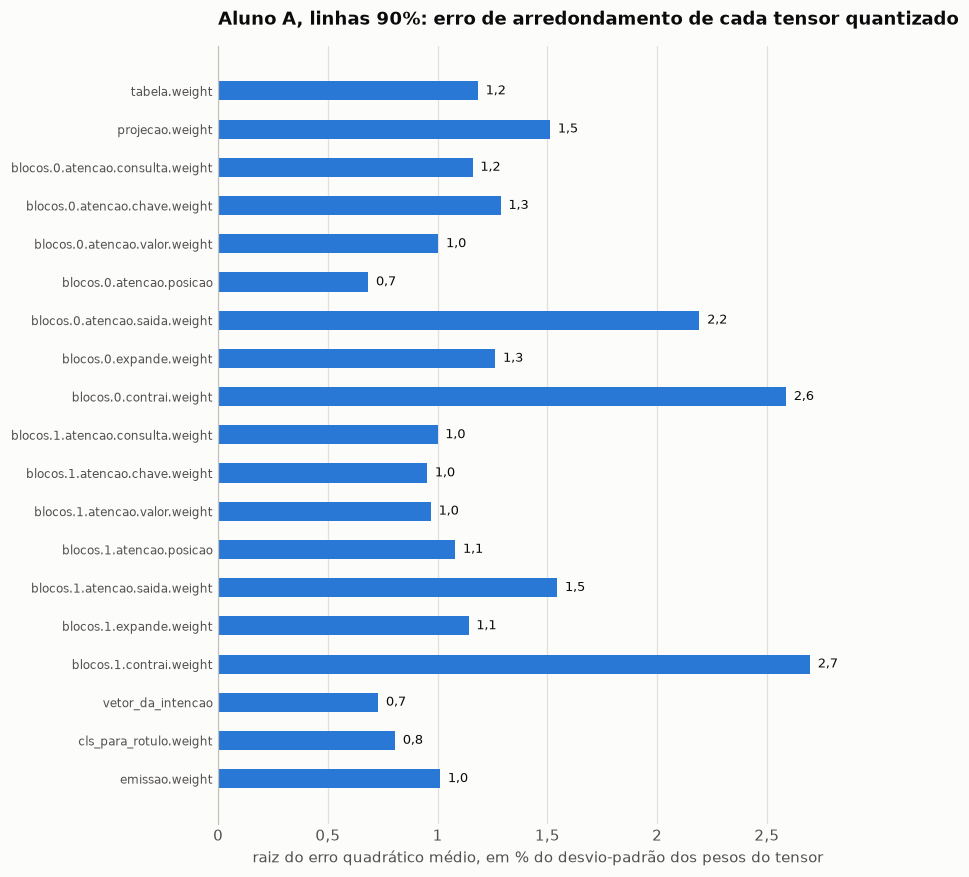

Zeros antes e depois de quantizar, somados nas 3 sementes (só nos tensores quantizados)


pesos em zero antes  \
modelo                 forma                                            
Aluno A, sem poda      INT8, quantização dinâmica                 384   
                       INT8, quantização estática                 384   
Aluno A, linhas 90%    INT8, quantização dinâmica                 384   
                       INT8, quantização estática                 384   
Aluno A, magnitude 95% INT8, quantização dinâmica          13.770.123   
                       INT8, quantização estática          13.770.123   
Teto, sem poda         INT8, quantização dinâmica                 384   
                       INT8, quantização estática                 384   
Teto, linhas 90%       INT8, quantização dinâmica                 384   
                       INT8, quantização estática                 384   
Teto, magnitude 90%    INT8, quantização dinâmica          13.045.395   
                       INT8, quantização estática          13.045.395   
Aluno B2, sem poda     INT8, quantização dinâmica                 384   
                       INT8, quantização estática                 384   
Aluno B2, linhas 90%   INT8, quantização dinâmica                 384   
                       INT8, quantização estática                 384   
Aluno B2, gradual 90%  INT8, quantização dinâmica          13.045.395   
                       INT8, quantização estática          13.045.395   

                                                  pesos em zero depois  \
modelo                 forma                                             
Aluno A, sem poda      INT8, quantização dinâmica              282.406   
                       INT8, quantização estática              282.406   
Aluno A, linhas 90%    INT8, quantização dinâmica              129.703   
                       INT8, quantização estática              129.703   
Aluno A, magnitude 95% INT8, quantização dinâmica           13.773.315   
                       INT8, quantização estática           13.773.315   
Teto, sem poda         INT8, quantização dinâmica              280.246   
                       INT8, quantização estática              280.246   
Teto, linhas 90%       INT8, quantização dinâmica              125.694   
                       INT8, quantização estática              125.694   
Teto, magnitude 90%    INT8, quantização dinâmica           13.048.553   
                       INT8, quantização estática           13.048.553   
Aluno B2, sem poda     INT8, quantização dinâmica              266.367   
                       INT8, quantização estática              266.367   
Aluno B2, linhas 90%   INT8, quantização dinâmica              113.313   
                       INT8, quantização estática              113.313   
Aluno B2, gradual 90%  INT8, quantização dinâmica           13.047.408   
                       INT8, quantização estática           13.047.408   

                                                  zeros que deixaram de ser zero  
modelo                 forma                                                      
Aluno A, sem poda      INT8, quantização dinâmica                              0  
                       INT8, quantização estática                              0  
Aluno A, linhas 90%    INT8, quantização dinâmica                              0  
                       INT8, quantização estática                              0  
Aluno A, magnitude 95% INT8, quantização dinâmica                              0  
                       INT8, quantização estática                              0  
Teto, sem poda         INT8, quantização dinâmica                              0  
                       INT8, quantização estática                              0  
Teto, linhas 90%       INT8, quantização dinâmica                              0  
                       INT8, quantização estática                              0  
Teto, magnitude 90%    INT8, quantização dinâmica                              0  
                       INT8, 

In [4]:
forma_da_mostra = "dinamica"
pesos = quantizacao.pesos_antes_e_depois(pasta_da_mostra / "fp32", pasta_da_mostra / forma_da_mostra)


TABELA, MATRIZES, RESTO = "Tabela de features", "Matrizes (projeção, encoder, cabeças)", "O que fica em 32 bits (vieses, normalizações, CLS)"


def parte(tensor):
    if tensor == "tabela.weight":
        return TABELA
    return MATRIZES if pesos.loc[tensor, "tipo_depois"] in ("int8", "uint8") else RESTO


por_parte = pesos.assign(parte=[parte(t) for t in pesos.index]).groupby("parte", sort=False).agg(
    tensores=("numeros", "size"), numeros=("numeros", "sum"), bytes_antes=("bytes_antes", "sum"), bytes_depois=("bytes_depois", "sum"))
arquivos = meta0[MOSTRA]["formas"][forma_da_mostra]["arquivos"]
print(f"{CURTO[MOSTRA]}, semente 0, {NOME_DA_FORMA[forma_da_mostra]}")
display(por_parte.assign(**{
    "números": por_parte["numeros"].map(n), "MB em 32 bits": por_parte["bytes_antes"].map(mb), "MB em 8 bits": por_parte["bytes_depois"].map(mb),
    "parte do arquivo de 32 bits": (por_parte["bytes_antes"] / por_parte["bytes_antes"].sum()).map(lambda v: pts(v) + "%"),
})[["tensores", "números", "MB em 32 bits", "MB em 8 bits", "parte do arquivo de 32 bits"]])

erro = quantizacao.erro_dos_pesos(pasta_da_mostra / "fp32", pasta_da_mostra / forma_da_mostra)
fig, ax = visual.barras_em_ordem(
    {t: 100 * erro.loc[t, "erro_relativo"] for t in erro.index},
    f"{CURTO[MOSTRA]}: erro de arredondamento de cada tensor quantizado", "raiz do erro quadrático médio, em % do desvio-padrão dos pesos do tensor",
    formato=lambda v: num(v, 1),
)
ax.tick_params(axis="y", labelsize=8)
visual.salvar(fig, PASTA, "erro_dos_pesos")
plt.show()

zeros = pd.DataFrame([
    {
        "modelo": CURTO[chave], "forma": NOME_DA_FORMA[forma],
        "pesos em zero antes": n(sum(e["meta"]["formas"][forma]["zeros_antes"] for e in exe[chave])),
        "pesos em zero depois": n(sum(e["meta"]["formas"][forma]["zeros_depois"] for e in exe[chave])),
        "zeros que deixaram de ser zero": n(sum(e["meta"]["formas"][forma]["zeros_perdidos"] for e in exe[chave])),
    }
    for chave in CHAVES for forma in CANDIDATAS
]).set_index(["modelo", "forma"])
zeros_conservados = all(e["meta"]["formas"][forma]["conservados"] for chave in CHAVES for e in exe[chave] for forma in FORMAS)
print("Zeros antes e depois de quantizar, somados nas 3 sementes (só nos tensores quantizados)")
display(zeros)

In [5]:
tabela_bytes = por_parte.loc[TABELA]
pior, melhor = erro["erro_relativo"].idxmax(), erro["erro_relativo"].idxmin()
com_zeros = [chave for chave in CHAVES if fichas[chave]["papel"] == "secundaria"]
display(Markdown(f"""
**Leitura.**

- **Onde está o tamanho.** A tabela de features é {pts(tabela_bytes['bytes_antes'] / por_parte['bytes_antes'].sum())}% dos pesos do arquivo de 32 bits: {mb(tabela_bytes['bytes_antes'])} MB, que viram {mb(tabela_bytes['bytes_depois'])} MB. As matrizes vão de {mb(por_parte.loc[MATRIZES, 'bytes_antes'])} para {mb(por_parte.loc[MATRIZES, 'bytes_depois'])} MB. O que fica em 32 bits soma {mb(por_parte.loc[RESTO, 'bytes_antes'])} MB.
- **O arquivo do sistema** tem ainda o vocabulário de features ({mb(arquivos[exportacao.FEATURES])} MB, em texto) e as transições do CRF ({mb(arquivos[exportacao.CRF])} MB). Esses não encolhem com a quantização.
- **O erro de arredondamento** vai de {num(100 * erro.loc[melhor, 'erro_relativo'], 1)}% do desvio-padrão dos pesos (`{melhor}`) a {num(100 * erro.loc[pior, 'erro_relativo'], 1)}% (`{pior}`). Na tabela de features é {num(100 * erro.loc['tabela.weight', 'erro_relativo'], 1)}%. O erro é maior onde poucos pesos muito grandes esticam a faixa: o degrau cresce para todos.
- **Os zeros.** {"Nenhum peso que era zero deixou de ser" if zeros_conservados else "**Há pesos que eram zero e deixaram de ser**"}, em nenhum modelo, semente ou forma. O número de zeros até cresce: pesos muito pequenos são arredondados para zero.{f" Nos modelos de pesos soltos ({', '.join(CURTO[c] for c in com_zeros)}), a máscara da poda sobrevive à quantização." if com_zeros else ""}
"""))


**Leitura.**

- **Onde está o tamanho.** A tabela de features é 16,4% dos pesos do arquivo de 32 bits: 1,29 MB, que viram 0,32 MB. As matrizes vão de 6,57 para 1,64 MB. O que fica em 32 bits soma 0,03 MB.
- **O arquivo do sistema** tem ainda o vocabulário de features (0,02 MB, em texto) e as transições do CRF (0,05 MB). Esses não encolhem com a quantização.
- **O erro de arredondamento** vai de 0,7% do desvio-padrão dos pesos (`blocos.0.atencao.posicao`) a 2,7% (`blocos.1.contrai.weight`). Na tabela de features é 1,2%. O erro é maior onde poucos pesos muito grandes esticam a faixa: o degrau cresce para todos.
- **Os zeros.** Nenhum peso que era zero deixou de ser, em nenhum modelo, semente ou forma. O número de zeros até cresce: pesos muito pequenos são arredondados para zero. Nos modelos de pesos soltos (Aluno A, magnitude 95%, Teto, magnitude 90%, Aluno B2, gradual 90%), a máscara da poda sobrevive à quantização.


## 5. Qualidade: cada forma contra o mesmo modelo em 32 bits

Toda diferença abaixo é "a forma menos o mesmo modelo em 32 bits no PyTorch", pareada, na média de 3 sementes. Primeiro em `dev`, que é onde as regras decidem; o teste vem na seção 8, só para a forma escolhida.

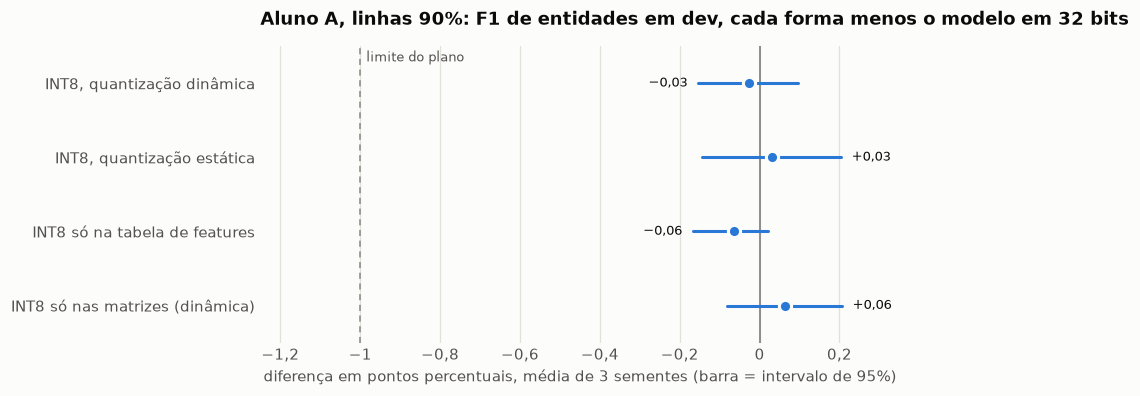

dev: diferença para o mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes


Acurácia de intenção  \
modelo                 forma                                                    
Aluno A, sem poda      INT8, quantização dinâmica       +0,10 (+0,02 a +0,20)   
                       INT8, quantização estática       +0,10 (−0,03 a +0,23)   
                       INT8 só na tabela de features    +0,05 (+0,00 a +0,11)   
                       INT8 só nas matrizes (dinâmica)  +0,13 (+0,05 a +0,23)   
Aluno A, linhas 90%    INT8, quantização dinâmica       +0,00 (−0,08 a +0,08)   
                       INT8, quantização estática       +0,02 (−0,13 a +0,16)   
                       INT8 só na tabela de features    −0,05 (−0,11 a +0,00)   
                       INT8 só nas matrizes (dinâmica)  −0,05 (−0,16 a +0,05)   
Aluno A, magnitude 95% INT8, quantização dinâmica       +0,03 (−0,08 a +0,16)   
                       INT8, quantização estática       −0,08 (−0,30 a +0,13)   
                       INT8 só na tabela de features    −0,05 (−0,13 a +0,02)   
                       INT8 só nas matrizes (dinâmica)  −0,00 (−0,13 a +0,13)   
Teto, sem poda         INT8, quantização dinâmica       +0,00 (−0,11 a +0,11)   
                       INT8, quantização estática       +0,07 (−0,10 a +0,23)   
                       INT8 só na tabela de features    −0,02 (−0,08 a +0,05)   
                       INT8 só nas matrizes (dinâmica)  +0,03 (−0,07 a +0,13)   
Teto, linhas 90%       INT8, quantização dinâmica       +0,08 (−0,03 a +0,20)   
                       INT8, quantização estática       +0,05 (−0,11 a +0,21)   
                       INT8 só na tabela de features    +0,00 (−0,07 a +0,07)   
                       INT8 só nas matrizes (dinâmica)  +0,07 (−0,07 a +0,20)   
Teto, magnitude 90%    INT8, quantização dinâmica       −0,08 (−0,20 a +0,02)   
                       INT8, quantização estática       −0,18 (−0,36 a −0,00)   
                       INT8 só na tabela de features    +0,02 (−0,03 a +0,08)   
                       INT8 só nas matrizes (dinâmica)  −0,08 (−0,20 a +0,03)   
Aluno B2, sem poda     INT8, quantização dinâmica       −0,03 (−0,16 a +0,10)   
                       INT8, quantização estática       −0,15 (−0,33 a +0,05)   
                       INT8 só na tabela de features    −0,07 (−0,15 a +0,00)   
                       INT8 só nas matrizes (dinâmica)  −0,07 (−0,18 a +0,03)   
Aluno B2, linhas 90%   INT8, quantização dinâmica       +0,08 (−0,05 a +0,21)   
                       INT8, quantização estática       −0,02 (−0,18 a +0,15)   
                       INT8 só na tabela de features    +0,02 (−0,08 a +0,11)   
                       INT8 só nas matrizes (dinâmica)  +0,00 (−0,13 a +0,11)   
Aluno B2, gradual 90%  INT8, quantização dinâmica       +0,03 (−0,08 a +0,16)   
                       INT8, quantização estática       +0,03 (−0,15 a +0,23)   
                       INT8 só na tabela de features    +0,00 (+0,00 a +0,00)   
                       INT8 só nas matrizes (dinâmica)  +0,07 (−0,03 a +0,18)   

                                                              F1 de entidades  \
modelo                 forma                                                    
Aluno A, sem poda      INT8, quantização dinâmica       −0,04 (−0,14 a +0,07)   
                       INT8, quantização estática       −0,04 (−0,19 a +0,12)   
                       INT8 só na tabela de features    +0,02 (−0,07 a +0,11)   
                       INT8 só nas matrizes (dinâmica)  −0,06 (−0,17 a +0,04)   
Aluno A, linhas 90%    INT8, quantização dinâmica       −0,03 (−0,15 a +0,10)   
                       INT8, quantização estática       +0,03 (−0,14 a +0,20)   
                       INT8 só na tabela de features    −0,06 (−0,17 a +0,02)   
                       INT8 só nas matrizes (dinâmica)  +0,06 (−0,08 a +0,21)   
Aluno A, magnitude 95% INT8, quantização dinâmica       +0,06 (−0,03 a +0,15)   
                       INT8, quantização estática       −0,05 (−0,23 a +0,11)   
      

In [6]:
COMPARADAS = ("fp32", *FORMAS)
contra = {
    "dev": {chave: {forma: qualidade.comparar_grupos(ouro_dev, grupo(chave, REFERENCIA, "dev"), grupo(chave, forma, "dev")) for forma in COMPARADAS} for chave in CHAVES},
}

fig, ax = diferencas(
    {NOME_DA_FORMA[forma]: trio(contra["dev"][MOSTRA][forma].loc["slot_f1"]) for forma in FORMAS},
    f"{CURTO[MOSTRA]}: F1 de entidades em dev, cada forma menos o modelo em 32 bits",
    "diferença em pontos percentuais, média de 3 sementes (barra = intervalo de 95%)", limite=-100 * LIMITE,
)
visual.salvar(fig, PASTA, "queda_por_forma")
plt.show()

print("dev: diferença para o mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes")
quadro_dev = pd.DataFrame([
    {"modelo": CURTO[chave], "forma": NOME_DA_FORMA[forma], **{qualidade.NOMES[m]: com_intervalo(contra["dev"][chave][forma].loc[m], 2) for m in TRES}}
    for chave in CHAVES for forma in FORMAS
]).set_index(["modelo", "forma"])
quadro_dev

In [7]:
quedas = {(chave, forma): contra["dev"][chave][forma].loc["slot_f1"] for chave in CHAVES for forma in FORMAS}
maior_queda = min(quedas, key=lambda k: quedas[k]["diferenca"])
distinguiveis = [(chave, forma, m) for chave in CHAVES for forma in CANDIDATAS for m in TRES if contra["dev"][chave][forma].loc[m, "distinguivel"]]
iguais_dev = {forma: np.mean([e["meta"]["formas"][forma]["iguais_ao_pytorch_dev"] / e["meta"]["pedidos"]["dev"] for chave in CHAVES for e in exe[chave]]) for forma in FORMAS}
so_tabela, so_matrizes = (np.mean([contra["dev"][chave][f].loc["slot_f1", "diferenca"] for chave in CHAVES]) for f in ("so_tabela", "so_matrizes"))
display(Markdown(f"""
**Leitura (dev).**

- **A maior queda de F1 de entidades** entre todos os modelos e formas é de {com_intervalo(quedas[maior_queda], 2)} pontos ({CURTO[maior_queda[0]]}, {NOME_DA_FORMA[maior_queda[1]]}). O limite do plano é de −{num(100 * LIMITE, 0)} ponto.
- **Diferenças distinguíveis de zero** nas formas que concorrem (intervalo de 95% todo de um lado): {"nenhuma, em nenhum modelo nem métrica" if not distinguiveis else "; ".join(f"{CURTO[c]}, {NOME_DA_FORMA[f]}, {qualidade.NOMES[m]}: {com_intervalo(contra['dev'][c][f].loc[m], 2)}" for c, f, m in distinguiveis)}.{acaso(len(distinguiveis), len(CHAVES) * len(CANDIDATAS) * len(TRES))}
- **Respostas inteiras iguais às do modelo em 32 bits**, na média dos modelos: {", ".join(f"{pts(v)}% com {NOME_DA_FORMA[f]}" for f, v in iguais_dev.items())}. A quantização muda poucas respostas, e muda para os dois lados: por isso a diferença nas métricas é menor que a parte das respostas que mudou.
- **Onde está o custo.** Na média dos modelos, quantizar só a tabela de features muda o F1 de entidades em {dif(so_tabela, 2)} ponto; só as matrizes, em {dif(so_matrizes, 2)}.
"""))


**Leitura (dev).**

- **A maior queda de F1 de entidades** entre todos os modelos e formas é de −0,26 (−0,52 a −0,02) pontos (Aluno B2, linhas 90%, INT8, quantização estática). O limite do plano é de −1 ponto.
- **Diferenças distinguíveis de zero** nas formas que concorrem (intervalo de 95% todo de um lado): Aluno A, sem poda, INT8, quantização dinâmica, Acurácia de intenção: +0,10 (+0,02 a +0,20); Teto, magnitude 90%, INT8, quantização estática, Acurácia de intenção: −0,18 (−0,36 a −0,00); Aluno B2, linhas 90%, INT8, quantização estática, F1 de entidades: −0,26 (−0,52 a −0,02). São 3 em 54 comparações; com intervalos de 95%, cerca de 2,7 sairia do zero só por acaso.
- **Respostas inteiras iguais às do modelo em 32 bits**, na média dos modelos: 98,9% com INT8, quantização dinâmica, 97,3% com INT8, quantização estática, 99,6% com INT8 só na tabela de features, 98,9% com INT8 só nas matrizes (dinâmica). A quantização muda poucas respostas, e muda para os dois lados: por isso a diferença nas métricas é menor que a parte das respostas que mudou.
- **Onde está o custo.** Na média dos modelos, quantizar só a tabela de features muda o F1 de entidades em +0,01 ponto; só as matrizes, em −0,01.


## 6. Tamanho

O tamanho é o dos arquivos gravados, com tudo o que o sistema precisa para responder: a rede, o vocabulário de features, o CRF e a ficha. "Compactado" é a mesma pasta com a rede passada pelo gzip; o sistema carrega dela direto, e responde igual (a execução confere).

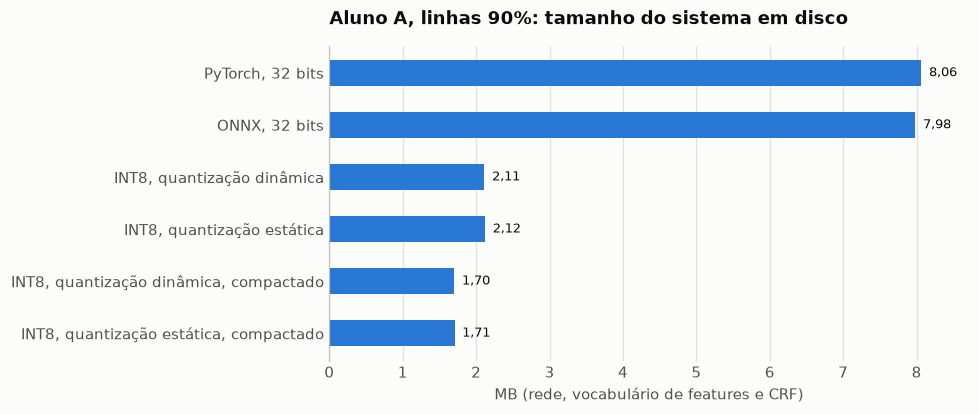

Tamanho em disco (MB), semente 0


,papel,"PyTorch, 32 bits","ONNX, 32 bits",INT8 dinâmica,INT8 estática,"INT8 dinâmica, compactado",32 bits ÷ INT8,32 bits ÷ INT8 compactado
modelo,,,,,,,,
"Aluno A, sem poda",sem poda,"19,92","19,84","5,26","5,27","4,35","3,8×","4,6×"
"Aluno A, linhas 90%",poda principal (menor arquivo),"8,06","7,98","2,11","2,12","1,70","3,8×","4,7×"
"Aluno A, magnitude 95%",poda secundária (pesos soltos),"19,92","19,84","5,26","5,27","0,92","3,8×","21,7×"
"Teto, sem poda",sem poda,"19,92","19,84","5,26","5,27","4,40","3,8×","4,5×"
"Teto, linhas 90%",poda principal (menor arquivo),"8,06","7,98","2,11","2,12","1,73","3,8×","4,7×"
"Teto, magnitude 90%",poda secundária (pesos soltos),"19,92","19,84","5,26","5,27","1,31","3,8×","15,2×"
"Aluno B2, sem poda",sem poda,"19,92","19,84","5,26","5,27","4,39","3,8×","4,5×"
"Aluno B2, linhas 90%",poda principal (menor arquivo),"8,06","7,98","2,11","2,12","1,72","3,8×","4,7×"
"Aluno B2, gradual 90%",poda secundária (pesos soltos),"19,92","19,84","5,26","5,27","1,26","3,8×","15,8×"


In [8]:
def tamanhos(chave):
    f = meta0[chave]["formas"]
    return {"pytorch": f[REFERENCIA]["bytes"], "fp32": f["fp32"]["bytes"], **{forma: f[forma]["bytes"] for forma in CANDIDATAS},
            **{f"{forma}_compactado": f[forma]["bytes_compactado"] for forma in CANDIDATAS}}


tam = {chave: tamanhos(chave) for chave in CHAVES}
fig, ax = visual.barras_em_ordem(
    {
        "PyTorch, 32 bits": tam[MOSTRA]["pytorch"] / 1e6, "ONNX, 32 bits": tam[MOSTRA]["fp32"] / 1e6,
        **{NOME_DA_FORMA[forma]: tam[MOSTRA][forma] / 1e6 for forma in CANDIDATAS},
        **{f"{NOME_DA_FORMA[forma]}, compactado": tam[MOSTRA][f"{forma}_compactado"] / 1e6 for forma in CANDIDATAS},
    },
    f"{CURTO[MOSTRA]}: tamanho do sistema em disco", "MB (rede, vocabulário de features e CRF)", formato=lambda v: num(v, 2),
)
visual.salvar(fig, PASTA, "tamanho")
plt.show()

compacta_igual = all(e["meta"]["formas"][forma]["compactado_responde_igual"] for chave in CHAVES for e in exe[chave] for forma in FORMAS)
print("Tamanho em disco (MB), semente 0")
pd.DataFrame([
    {
        "modelo": CURTO[chave], "papel": PAPEL[fichas[chave]["papel"]], "PyTorch, 32 bits": mb(tam[chave]["pytorch"]), "ONNX, 32 bits": mb(tam[chave]["fp32"]),
        "INT8 dinâmica": mb(tam[chave]["dinamica"]), "INT8 estática": mb(tam[chave]["estatica"]),
        "INT8 dinâmica, compactado": mb(tam[chave]["dinamica_compactado"]),
        "32 bits ÷ INT8": num(tam[chave]["pytorch"] / tam[chave]["dinamica"], 1) + "×",
        "32 bits ÷ INT8 compactado": num(tam[chave]["pytorch"] / tam[chave]["dinamica_compactado"], 1) + "×",
    }
    for chave in CHAVES
]).set_index("modelo")

In [9]:
t = tam[MOSTRA]
linhas_de_leitura = [
    f"- **{CURTO[MOSTRA]}:** de {mb(t['pytorch'])} MB em 32 bits para {mb(t['dinamica'])} MB em INT8, {num(t['pytorch'] / t['dinamica'], 1)} vezes menos. "
    f"Não chega a 4 vezes porque o vocabulário de features, o CRF e os vieses não encolhem: juntos são {mb(t['dinamica'] - por_parte.loc[[TABELA, MATRIZES], 'bytes_depois'].sum())} MB do arquivo final.",
    f"- **Dinâmica e estática** guardam os mesmos pesos: a diferença entre os dois arquivos é de {num(abs(t['estatica'] - t['dinamica']) / 1e3, 1)} KB (as faixas das ativações, que a estática grava).",
]
for chave in com_zeros:
    s = tam[chave]
    linhas_de_leitura.append(
        f"- **{CURTO[chave]}** ({pts(esparsidade[chave])}% dos pesos em zero): o arquivo INT8 tem {mb(s['dinamica'])} MB, o mesmo de um modelo sem zeros, "
        f"porque um zero ocupa um byte. Compactado, vai a {mb(s['dinamica_compactado'])} MB ({num(s['pytorch'] / s['dinamica_compactado'], 1)} vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece."
    )
sem_zeros = [chave for chave in CHAVES if chave not in com_zeros]
if sem_zeros:
    ganho = np.mean([1 - tam[c]["dinamica_compactado"] / tam[c]["dinamica"] for c in sem_zeros])
    linhas_de_leitura.append(f"- Nos modelos sem pesos soltos em zero, compactar tira em média {pts(ganho)}% do arquivo INT8: o compressor aproveita os pesos pequenos que viraram zero e o texto do vocabulário.")
linhas_de_leitura.append(f"- O sistema carregado do arquivo compactado responde igual ao do arquivo comum: {'confere em todas as execuções' if compacta_igual else '**NÃO confere**'}.")
display(Markdown("**Leitura.**\n\n" + "\n".join(linhas_de_leitura)))

**Leitura.**

- **Aluno A, linhas 90%:** de 8,06 MB em 32 bits para 2,11 MB em INT8, 3,8 vezes menos. Não chega a 4 vezes porque o vocabulário de features, o CRF e os vieses não encolhem: juntos são 0,15 MB do arquivo final.
- **Dinâmica e estática** guardam os mesmos pesos: a diferença entre os dois arquivos é de 8,3 KB (as faixas das ativações, que a estática grava).
- **Aluno A, magnitude 95%** (94,1% dos pesos em zero): o arquivo INT8 tem 5,26 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 0,92 MB (21,7 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Teto, magnitude 90%** (89,2% dos pesos em zero): o arquivo INT8 tem 5,26 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 1,31 MB (15,2 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Aluno B2, gradual 90%** (89,2% dos pesos em zero): o arquivo INT8 tem 5,26 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 1,26 MB (15,8 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- Nos modelos sem pesos soltos em zero, compactar tira em média 17,7% do arquivo INT8: o compressor aproveita os pesos pequenos que viraram zero e o texto do vocabulário.
- O sistema carregado do arquivo compactado responde igual ao do arquivo comum: confere em todas as execuções.

## 7. Latência

Protocolo da Etapa 2 (`avaliacao/eficiencia.py`): uma consulta por vez, 1 thread, do texto à resposta, 1.024 consultas medidas depois de 50 de aquecimento, com os pedidos de `dev`. Aqui são 5 rodadas, alternando os sistemas, com o modelo da semente 0. A medida roda fora do notebook (`uv run python -m especialista.experimentos.etapa8 latencia`), com a máquina quieta.

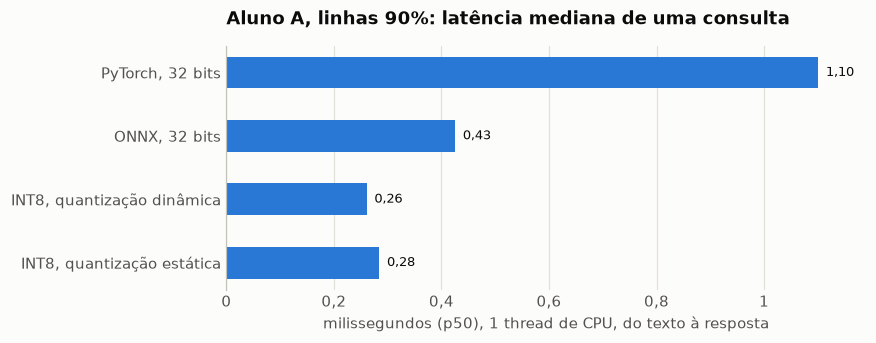

Latência em milissegundos, semente 0: p50 (do menor ao maior p50 entre as 5 rodadas) e p95


,"PyTorch, 32 bits","ONNX, 32 bits","INT8, quantização dinâmica","INT8, quantização estática"
modelo,,,,
"Aluno A, sem poda","1,11 (1,10 a 1,11); p95 1,55","0,42 (0,41 a 0,45); p95 0,71","0,26 (0,25 a 0,28); p95 0,45","0,28 (0,28 a 0,30); p95 0,48"
"Aluno A, linhas 90%","1,10 (1,09 a 1,11); p95 1,54","0,43 (0,41 a 0,44); p95 0,71","0,26 (0,25 a 0,28); p95 0,46","0,28 (0,28 a 0,30); p95 0,48"
"Aluno A, magnitude 95%","1,10 (1,08 a 1,13); p95 1,55","0,44 (0,42 a 0,46); p95 0,74","0,27 (0,25 a 0,29); p95 0,47","0,29 (0,28 a 0,31); p95 0,49"
"Teto, sem poda","1,10 (1,08 a 1,12); p95 1,54","0,43 (0,42 a 0,45); p95 0,71","0,27 (0,25 a 0,29); p95 0,46","0,29 (0,28 a 0,31); p95 0,49"
"Teto, linhas 90%","1,10 (1,09 a 1,12); p95 1,52","0,43 (0,41 a 0,45); p95 0,70","0,26 (0,25 a 0,27); p95 0,44","0,28 (0,27 a 0,29); p95 0,47"
"Teto, magnitude 90%","1,10 (1,09 a 1,12); p95 1,52","0,43 (0,42 a 0,46); p95 0,71","0,27 (0,26 a 0,29); p95 0,46","0,29 (0,28 a 0,30); p95 0,49"
"Aluno B2, sem poda","1,11 (1,09 a 1,13); p95 1,54","0,44 (0,43 a 0,44); p95 0,73","0,27 (0,26 a 0,28); p95 0,47","0,29 (0,28 a 0,30); p95 0,50"
"Aluno B2, linhas 90%","1,10 (1,09 a 1,11); p95 1,54","0,42 (0,41 a 0,44); p95 0,71","0,26 (0,25 a 0,28); p95 0,46","0,28 (0,27 a 0,29); p95 0,48"
"Aluno B2, gradual 90%","1,11 (1,10 a 1,12); p95 1,56","0,43 (0,41 a 0,45); p95 0,73","0,27 (0,26 a 0,29); p95 0,48","0,29 (0,28 a 0,32); p95 0,50"


In [10]:
p50 = {chave: {forma: lat[chave]["resumo"][forma]["latencia_p50_ms"] for forma in etapa8.COM_LATENCIA} for chave in CHAVES}
p95 = {chave: {forma: lat[chave]["resumo"][forma]["latencia_p95_ms"] for forma in etapa8.COM_LATENCIA} for chave in CHAVES}
rodadas = {chave: lat[chave]["p50_por_rodada_ms"] for chave in CHAVES}

# A máquina estava quieta? Duas conferências: quanto de CPU os outros processos usaram durante cada medida (o pior caso),
# e o teto sem poda contra a latência que a Etapa 4b mediu.
outros_processos = max(l["nucleos_de_outros"] for l in lat.values())   # em núcleos de CPU
LIMITE_DE_OUTROS = 0.25
teto_na_4b = float(resultados.carregar(ENTREGAS / "04b_intencao").query("particao == 'test'").iloc[0]["latencia_p50_ms"])
teto_agora = p50[("teto", "sem_poda")][REFERENCIA] if ("teto", "sem_poda") in p50 else None
maquina_quieta = bool(outros_processos <= LIMITE_DE_OUTROS and (teto_agora is None or teto_agora <= 1.2 * teto_na_4b))

fig, ax = visual.barras_em_ordem(
    {NOME_DA_FORMA[forma]: p50[MOSTRA][forma] for forma in etapa8.COM_LATENCIA},
    f"{CURTO[MOSTRA]}: latência mediana de uma consulta", "milissegundos (p50), 1 thread de CPU, do texto à resposta", formato=lambda v: num(v, 2),
)
visual.salvar(fig, PASTA, "latencia")
plt.show()

print("Latência em milissegundos, semente 0: p50 (do menor ao maior p50 entre as 5 rodadas) e p95")
celula = lambda chave, forma: f"{num(p50[chave][forma], 2)} ({num(min(rodadas[chave][forma]), 2)} a {num(max(rodadas[chave][forma]), 2)}); p95 {num(p95[chave][forma], 2)}"
pd.DataFrame([{"modelo": CURTO[chave], **{NOME_DA_FORMA[forma]: celula(chave, forma) for forma in etapa8.COM_LATENCIA}} for chave in CHAVES]).set_index("modelo")

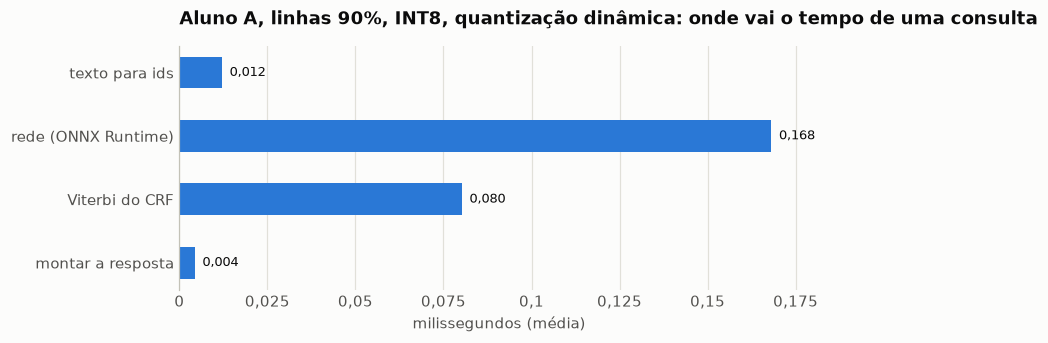

Aluno A, linhas 90%: tempo médio de cada trecho de uma consulta (ms)


,"ONNX, 32 bits","INT8, quantização dinâmica","INT8, quantização estática"
texto para ids,"0,014","0,012","0,013"
rede (ONNX Runtime),"0,324","0,168","0,197"
Viterbi do CRF,"0,084","0,080","0,082"
montar a resposta,"0,006","0,004","0,005"



**Leitura.**

- **A máquina estava quieta?** Sim. Durante as medidas, os outros processos da máquina ocuparam no máximo 0,05 núcleo de CPU, dos 24 que ela tem (o limite da etapa é 0,25). O teto sem poda, em PyTorch, deu 1,10 ms; na Etapa 4b, 1,20 ms.
- **Sair do PyTorch** é o que mais muda a latência: na média dos modelos, o ONNX de 32 bits é 2,6 vezes mais rápido que o mesmo modelo em PyTorch. Com um pedido de poucas palavras as contas são pequenas, e o que pesa no PyTorch é o custo fixo de cada operação.
- **Passar para 8 bits**, na média dos modelos, deixa a consulta 1,62 vezes mais rápida com INT8, quantização dinâmica, 1,50 vezes mais rápida com INT8, quantização estática, em relação ao ONNX de 32 bits (menos de 1 = mais lenta).
- **Estática contra dinâmica:** a estática é mais rápida em todas as rodadas em 0 de 9 modelos; a dinâmica, em 9.
- **Onde vai o tempo** (Aluno A, linhas 90%, INT8, quantização dinâmica): a rede leva 63% da consulta e o Viterbi, 30%. A quantização só mexe no primeiro.


In [11]:
trechos = pd.DataFrame({NOME_DA_FORMA[forma]: lat[MOSTRA]["tempo_por_trecho_ms"][forma] for forma in ("fp32", *CANDIDATAS)})
fig, ax = visual.barras_em_ordem(
    dict(trechos[NOME_DA_FORMA["dinamica"]]), f"{CURTO[MOSTRA]}, {NOME_DA_FORMA['dinamica']}: onde vai o tempo de uma consulta", "milissegundos (média)",
    formato=lambda v: num(v, 3),
)
visual.salvar(fig, PASTA, "tempo_por_trecho")
plt.show()
print(f"{CURTO[MOSTRA]}: tempo médio de cada trecho de uma consulta (ms)")
display(trechos.map(lambda v: num(v, 3)))

ganho_onnx = np.mean([p50[c][REFERENCIA] / p50[c]["fp32"] for c in CHAVES])
ganho_int8 = {forma: np.mean([p50[c]["fp32"] / p50[c][forma] for c in CHAVES]) for forma in CANDIDATAS}
estatica_mais_rapida = [c for c in CHAVES if all(e < d for e, d in zip(rodadas[c]["estatica"], rodadas[c]["dinamica"]))]
dinamica_mais_rapida = [c for c in CHAVES if all(d < e for e, d in zip(rodadas[c]["estatica"], rodadas[c]["dinamica"]))]
d = trechos[NOME_DA_FORMA["dinamica"]]
display(Markdown(f"""
**Leitura.**

- **A máquina estava quieta?** {"Sim" if maquina_quieta else "**Não**"}. Durante as medidas, os outros processos da máquina ocuparam no máximo {num(outros_processos, 2)} núcleo de CPU, dos {etapa8.ambiente()["cpus_logicas"]} que ela tem (o limite da etapa é {num(LIMITE_DE_OUTROS, 2)}).{f" O teto sem poda, em PyTorch, deu {num(teto_agora, 2)} ms; na Etapa 4b, {num(teto_na_4b, 2)} ms." if teto_agora is not None else ""}{"" if maquina_quieta else " **As latências abaixo estão infladas e não valem como resultado.**"}
- **Sair do PyTorch** é o que mais muda a latência: na média dos modelos, o ONNX de 32 bits é {num(ganho_onnx, 1)} vezes mais rápido que o mesmo modelo em PyTorch. Com um pedido de poucas palavras as contas são pequenas, e o que pesa no PyTorch é o custo fixo de cada operação.
- **Passar para 8 bits**, na média dos modelos, deixa a consulta {", ".join(f"{num(v, 2)} vezes mais rápida com {NOME_DA_FORMA[f]}" for f, v in ganho_int8.items())}, em relação ao ONNX de 32 bits (menos de 1 = mais lenta).
- **Estática contra dinâmica:** a estática é mais rápida em todas as rodadas em {len(estatica_mais_rapida)} de {len(CHAVES)} modelos; a dinâmica, em {len(dinamica_mais_rapida)}.
- **Onde vai o tempo** ({CURTO[MOSTRA]}, {NOME_DA_FORMA["dinamica"]}): a rede leva {pts(d["rede (ONNX Runtime)"] / d.sum(), 0)}% da consulta e o Viterbi, {pts(d["Viterbi do CRF"] / d.sum(), 0)}%. A quantização só mexe no primeiro.
"""))

## 8. A forma final de cada modelo

A regra da seção 2 (itens 11 e 12), aplicada a cada modelo em `dev`. Depois, o teste, para a forma escolhida.

A regra em dev: F1 de entidades de cada forma menos o do mesmo modelo em 32 bits (intervalo de 95%)


,"INT8, quantização dinâmica: queda","INT8, quantização estática: queda","INT8, quantização dinâmica: passa","INT8, quantização estática: passa",fica,por quê
modelo,,,,,,
"Aluno A, sem poda","−0,04 (−0,14 a +0,07)","−0,04 (−0,19 a +0,12)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Aluno A, linhas 90%","−0,03 (−0,15 a +0,10)","+0,03 (−0,14 a +0,20)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Aluno A, magnitude 95%","+0,06 (−0,03 a +0,15)","−0,05 (−0,23 a +0,11)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Teto, sem poda","−0,01 (−0,13 a +0,11)","−0,10 (−0,27 a +0,07)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Teto, linhas 90%","−0,01 (−0,13 a +0,11)","−0,11 (−0,30 a +0,07)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Teto, magnitude 90%","+0,06 (−0,10 a +0,22)","−0,14 (−0,36 a +0,08)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Aluno B2, sem poda","−0,03 (−0,17 a +0,11)","−0,02 (−0,24 a +0,19)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Aluno B2, linhas 90%","−0,02 (−0,20 a +0,15)","−0,26 (−0,52 a −0,02)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"
"Aluno B2, gradual 90%","−0,07 (−0,20 a +0,04)","−0,22 (−0,45 a +0,00)",sim,sim,"INT8, quantização dinâmica","as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples"


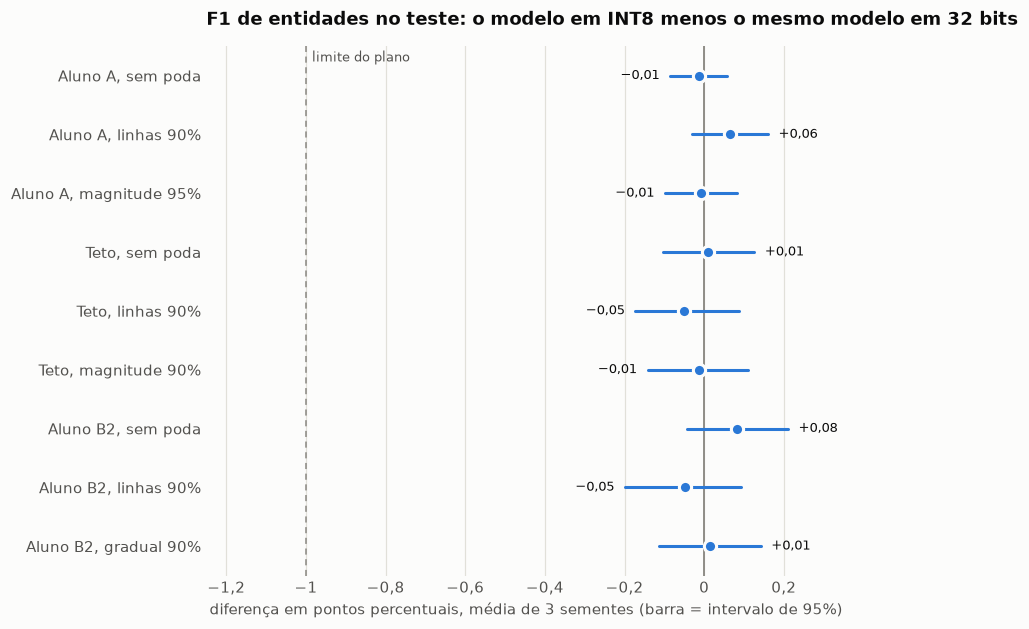

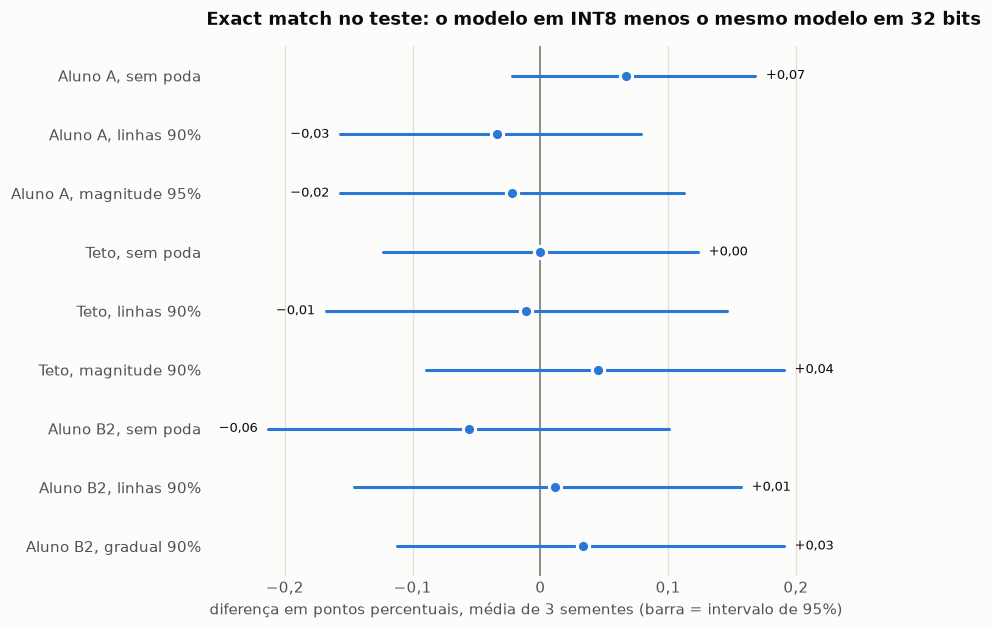

Teste, em % (intervalo de 95%), média de 3 sementes: o modelo em 32 bits, o mesmo em INT8 e a diferença pareada


32 bits  \
modelo                 forma                      métrica                                    
Aluno A, sem poda      INT8, quantização dinâmica Acurácia de intenção  80,7 (79,4 a 82,0)   
                                                  Macro-F1 de intenção  78,3 (76,4 a 80,7)   
                                                  F1 de entidades       64,8 (63,2 a 66,5)   
                                                  Exact match           51,2 (49,6 a 52,9)   
Aluno A, linhas 90%    INT8, quantização dinâmica Acurácia de intenção  80,2 (78,9 a 81,5)   
                                                  Macro-F1 de intenção  77,6 (75,8 a 80,0)   
                                                  F1 de entidades       64,8 (63,3 a 66,4)   
                                                  Exact match           51,3 (49,6 a 52,9)   
Aluno A, magnitude 95% INT8, quantização dinâmica Acurácia de intenção  79,9 (78,6 a 81,2)   
                                                  Macro-F1 de intenção  77,2 (75,1 a 79,7)   
                                                  F1 de entidades       64,3 (62,7 a 66,0)   
                                                  Exact match           50,3 (48,6 a 52,0)   
Teto, sem poda         INT8, quantização dinâmica Acurácia de intenção  84,4 (83,2 a 85,6)   
                                                  Macro-F1 de intenção  82,8 (81,0 a 84,8)   
                                                  F1 de entidades       73,6 (72,2 a 75,1)   
                                                  Exact match           62,5 (60,8 a 64,1)   
Teto, linhas 90%       INT8, quantização dinâmica Acurácia de intenção  83,4 (82,2 a 84,6)   
                                                  Macro-F1 de intenção  81,4 (79,6 a 83,4)   
                                                  F1 de entidades       73,5 (72,0 a 74,9)   
                                                  Exact match           61,3 (59,6 a 62,9)   
Teto, magnitude 90%    INT8, quantização dinâmica Acurácia de intenção  83,8 (82,6 a 85,0)   
                                                  Macro-F1 de intenção  82,0 (80,1 a 84,0)   
                                                  F1 de entidades       73,4 (71,9 a 74,9)   
                                                  Exact match           61,6 (59,9 a 63,2)   
Aluno B2, sem poda     INT8, quantização dinâmica Acurácia de intenção  77,8 (76,3 a 79,3)   
                                                  Macro-F1 de intenção  76,5 (74,6 a 78,7)   
                                                  F1 de entidades       58,0 (56,3 a 59,8)   
                                                  Exact match           46,0 (44,2 a 47,6)   
Aluno B2, linhas 90%   INT8, quantização dinâmica Acurácia de intenção  77,8 (76,4 a 79,2)   
                                                  Macro-F1 de intenção  76,3 (74,5 a 78,7)   
                                                  F1 de entidades       58,0 (56,2 a 59,8)   
                                                  Exact match           46,2 (44,5 a 47,9)   
Aluno B2, gradual 90%  INT8, quantização dinâmica Acurácia de intenção  77,5 (76,1 a 78,9)   
                                                  Macro-F1 de intenção  76,0 (74,1 a 78,4)   
                                                  F1 de entidades       58,6 (56,9 a 60,3)   
                                                  Exact match           46,1 (44,3 a 47,8)   

                                                                                      INT8  \
modelo                 forma                      métrica                                    
Aluno A, sem poda      INT8, quantização dinâmica Acurácia de intenção  80,7 (79,3 a 82,0)   
                                                  Macro-F1 de intenção  78,3 (76,4 a 80,8)   
                                                  F1 de entidades       64,8 (63,2 a 66,5)   
                                        

In [12]:
decisoes = {
    chave: etapa8.escolher_forma(ouro_dev, {forma: grupo(chave, forma, "dev") for forma in (REFERENCIA, *CANDIDATAS)}, rodadas[chave])
    for chave in CHAVES
}
ESCOLHIDA = {chave: decisoes[chave]["forma"] for chave in CHAVES}
precisam_de_qat = [chave for chave in CHAVES if decisoes[chave]["precisa_de_qat"]]

print("A regra em dev: F1 de entidades de cada forma menos o do mesmo modelo em 32 bits (intervalo de 95%)")
display(pd.DataFrame([
    {
        "modelo": CURTO[chave],
        **{f"{NOME_DA_FORMA[forma]}: queda": com_intervalo(decisoes[chave]["tabela"].loc[forma], 2) for forma in CANDIDATAS},
        **{f"{NOME_DA_FORMA[forma]}: passa": "sim" if decisoes[chave]["tabela"].loc[forma, "passa"] else "NÃO" for forma in CANDIDATAS},
        "fica": NOME_DA_FORMA[ESCOLHIDA[chave]] if ESCOLHIDA[chave] else "nenhuma: QAT", "por quê": decisoes[chave]["motivo"],
    }
    for chave in CHAVES
]).set_index("modelo"))

# O teste, para a forma escolhida de cada modelo (e para o ONNX de 32 bits, que tem de dar zero)
com_forma = [chave for chave in CHAVES if ESCOLHIDA[chave]]
contra["test"] = {
    chave: {forma: qualidade.comparar_grupos(ouro_teste, grupo(chave, REFERENCIA, "test"), grupo(chave, forma, "test")) for forma in ("fp32", ESCOLHIDA[chave])}
    for chave in com_forma
}
medidas = {
    particao: {chave: {forma: qualidade.intervalo_do_grupo(gabarito[particao], grupo(chave, forma, particao)) for forma in (REFERENCIA, ESCOLHIDA[chave])} for chave in com_forma}
    for particao in ("dev", "test")
}
if com_forma:
    fig, ax = diferencas(
        {CURTO[chave]: trio(contra["test"][chave][ESCOLHIDA[chave]].loc["slot_f1"]) for chave in com_forma},
        "F1 de entidades no teste: o modelo em INT8 menos o mesmo modelo em 32 bits", "diferença em pontos percentuais, média de 3 sementes (barra = intervalo de 95%)",
        limite=-100 * LIMITE,
    )
    visual.salvar(fig, PASTA, "queda_no_teste")
    plt.show()
    fig, ax = diferencas(
        {CURTO[chave]: trio(contra["test"][chave][ESCOLHIDA[chave]].loc["exact_match"]) for chave in com_forma},
        "Exact match no teste: o modelo em INT8 menos o mesmo modelo em 32 bits", "diferença em pontos percentuais, média de 3 sementes (barra = intervalo de 95%)",
    )
    visual.salvar(fig, PASTA, "queda_no_teste_exact_match")
    plt.show()

print("Teste, em % (intervalo de 95%), média de 3 sementes: o modelo em 32 bits, o mesmo em INT8 e a diferença pareada")
linhas_do_teste = [
    {
        "modelo": CURTO[chave], "forma": NOME_DA_FORMA[ESCOLHIDA[chave]], "métrica": qualidade.NOMES[m],
        "32 bits": valor_com_intervalo(medidas["test"][chave][REFERENCIA].loc[m]), "INT8": valor_com_intervalo(medidas["test"][chave][ESCOLHIDA[chave]].loc[m]),
        "INT8 − 32 bits": com_intervalo(contra["test"][chave][ESCOLHIDA[chave]].loc[m], 2),
    }
    for chave in com_forma for m in qualidade.METRICAS
]
pd.DataFrame(linhas_do_teste).set_index(["modelo", "forma", "métrica"]) if linhas_do_teste else None

In [13]:
def frase_do_modelo(chave):
    if decisoes[chave]["precisa_de_qat"]:
        return f"**{CURTO[chave]}:** nenhuma forma pós-treino passa. Pela regra do plano, este modelo precisa de treino ciente de quantização."
    forma, t = ESCOLHIDA[chave], contra["test"][chave][ESCOLHIDA[chave]]
    return (f"**{CURTO[chave]}:** fica a {NOME_DA_FORMA[forma]} ({decisoes[chave]['motivo']}). No teste, em relação ao mesmo modelo em 32 bits: "
            f"{com_intervalo(t.loc['intent_acc'], 2)} em intenção, {com_intervalo(t.loc['slot_f1'], 2)} em entidades e {com_intervalo(t.loc['exact_match'], 2)} em exact match.")


distinguiveis_no_teste = [(chave, m) for chave in com_forma for m in TRES if contra["test"][chave][ESCOLHIDA[chave]].loc[m, "distinguivel"]]
if precisam_de_qat:
    frase_do_qat = ("**Treino ciente de quantização:** a regra do plano manda fazer para " + ", ".join(CURTO[c] for c in precisam_de_qat)
                    + ". Esta etapa não fecha sem ele.")
else:
    frase_do_qat = (f"**Treino ciente de quantização:** não entra. Em nenhum modelo o F1 de entidades caiu mais de {num(100 * LIMITE, 0)} ponto em `dev` "
                    "com a quantização pós-treino, que era a condição do plano.")
if FINAL is None:
    frase_do_final = "**A Etapa 7 ainda não marcou o modelo principal do projeto**; sem a decisão dela, esta etapa não tem modelo final."
elif ESCOLHIDA[FINAL] is None:
    frase_do_final = f"**O modelo final do projeto** seria o {CURTO[FINAL]}, mas ele não passou na regra: depende do treino ciente de quantização."
else:
    frase_do_final = (f"**O modelo final do projeto** é o **{fichas[FINAL]['nome']}, em {NOME_DA_FORMA[ESCOLHIDA[FINAL]]}**: "
                      f"{mb(tam[FINAL][ESCOLHIDA[FINAL]])} MB em disco e {num(p50[FINAL][ESCOLHIDA[FINAL]], 2)} ms por consulta (p50), "
                      f"contra {mb(tam[FINAL]['pytorch'])} MB e {num(p50[FINAL][REFERENCIA], 2)} ms do mesmo modelo em 32 bits no PyTorch.")
# A variante de pesos soltos do modelo principal: menor no disco depois do zip, mas não na memória
SECUNDARIA = next((c for c in CHAVES if FINAL and c[0] == FINAL[0] and fichas[c]["papel"] == "secundaria" and ESCOLHIDA[c]), None)
frase_da_secundaria = ""
if SECUNDARIA and ESCOLHIDA[FINAL]:
    f_final, f_sec = ESCOLHIDA[FINAL], ESCOLHIDA[SECUNDARIA]
    entre_variantes = qualidade.comparar_grupos(ouro_teste, grupo(FINAL, f_final, "test"), grupo(SECUNDARIA, f_sec, "test")).loc["exact_match"]   # pesos soltos − final
    onde = {"acima": "acima do", "abaixo": "abaixo do", "sem diferença distinguível": "sem diferença distinguível para o"}[posicao(entre_variantes)]
    frase_da_secundaria = (
        f"**A variante de pesos soltos do mesmo modelo** ({CURTO[SECUNDARIA]}) fica com {mb(tam[SECUNDARIA][f_sec + '_compactado'])} MB em INT8 compactado, "
        f"{'menos' if tam[SECUNDARIA][f_sec + '_compactado'] < tam[FINAL][f_final + '_compactado'] else 'mais'} que o modelo final "
        f"({mb(tam[FINAL][f_final])} MB, ou {mb(tam[FINAL][f_final + '_compactado'])} MB compactado). Isso vale só para o disco: sem compactar, e na memória depois de carregada, "
        f"ela ocupa os mesmos {mb(tam[SECUNDARIA][f_sec])} MB de um modelo sem poda, e a latência é {num(p50[SECUNDARIA][f_sec], 2)} ms. "
        f"No teste, em exact match, ela fica {onde} modelo final ({com_intervalo(entre_variantes, 2)}). "
        "O modelo final continua sendo a variante que a Etapa 7 marcou como principal: a regra foi escrita antes da medida."
    )
display(Markdown("**Decisão.**\n\n" + "\n".join(f"- {frase_do_modelo(chave)}" for chave in CHAVES) + f"""
- **Diferenças distinguíveis de zero no teste**, na forma escolhida: {"nenhuma" if not distinguiveis_no_teste else "; ".join(f"{CURTO[c]}, {qualidade.NOMES[m]}: {com_intervalo(contra['test'][c][ESCOLHIDA[c]].loc[m], 2)}" for c, m in distinguiveis_no_teste)}.{acaso(len(distinguiveis_no_teste), len(com_forma) * len(TRES))}
- {frase_do_qat}
- {frase_do_final}
""" + (f"- {frase_da_secundaria}\n" if frase_da_secundaria else "")))

**Decisão.**

- **Aluno A, sem poda:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: −0,03 (−0,13 a +0,06) em intenção, −0,01 (−0,09 a +0,06) em entidades e +0,07 (−0,02 a +0,17) em exact match.
- **Aluno A, linhas 90%:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: −0,01 (−0,10 a +0,08) em intenção, +0,06 (−0,03 a +0,16) em entidades e −0,03 (−0,16 a +0,08) em exact match.
- **Aluno A, magnitude 95%:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: −0,03 (−0,13 a +0,06) em intenção, −0,01 (−0,10 a +0,08) em entidades e −0,02 (−0,16 a +0,11) em exact match.
- **Teto, sem poda:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: −0,04 (−0,13 a +0,03) em intenção, +0,01 (−0,10 a +0,13) em entidades e +0,00 (−0,12 a +0,12) em exact match.
- **Teto, linhas 90%:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: −0,06 (−0,18 a +0,07) em intenção, −0,05 (−0,17 a +0,09) em entidades e −0,01 (−0,17 a +0,15) em exact match.
- **Teto, magnitude 90%:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: +0,11 (+0,02 a +0,21) em intenção, −0,01 (−0,14 a +0,11) em entidades e +0,04 (−0,09 a +0,19) em exact match.
- **Aluno B2, sem poda:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: +0,06 (−0,06 a +0,17) em intenção, +0,08 (−0,04 a +0,21) em entidades e −0,06 (−0,21 a +0,10) em exact match.
- **Aluno B2, linhas 90%:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: −0,02 (−0,12 a +0,08) em intenção, −0,05 (−0,20 a +0,09) em entidades e +0,01 (−0,15 a +0,16) em exact match.
- **Aluno B2, gradual 90%:** fica a INT8, quantização dinâmica (as duas passam, sem diferença distinguível de qualidade, e a estática não é mais rápida em todas as rodadas: fica a mais simples). No teste, em relação ao mesmo modelo em 32 bits: +0,00 (−0,11 a +0,11) em intenção, +0,01 (−0,11 a +0,14) em entidades e +0,03 (−0,11 a +0,19) em exact match.
- **Diferenças distinguíveis de zero no teste**, na forma escolhida: Teto, magnitude 90%, Acurácia de intenção: +0,11 (+0,02 a +0,21). É 1 em 27 comparações; com intervalos de 95%, cerca de 1,4 sairia do zero só por acaso.
- **Treino ciente de quantização:** não entra. Em nenhum modelo o F1 de entidades caiu mais de 1 ponto em `dev` com a quantização pós-treino, que era a condição do plano.
- **O modelo final do projeto** é o **Aluno A (rótulos do Claude Haiku 5.5), sem 90% das linhas da tabela de features, em INT8, quantização dinâmica**: 2,11 MB em disco e 0,26 ms por consulta (p50), contra 8,06 MB e 1,10 ms do mesmo modelo em 32 bits no PyTorch.
- **A variante de pesos soltos do mesmo modelo** (Aluno A, magnitude 95%) fica com 0,92 MB em INT8 compactado, menos que o modelo final (2,11 MB, ou 1,70 MB compactado). Isso vale só para o disco: sem compactar, e na memória depois de carregada, ela ocupa os mesmos 5,26 MB de um modelo sem poda, e a latência é 0,27 ms. No teste, em exact match, ela fica abaixo do modelo final (−0,96 (−1,84 a −0,01)). O modelo final continua sendo a variante que a Etapa 7 marcou como principal: a regra foi escrita antes da medida.


## 9. Entrega

Vai para a entrega o sistema de cada modelo na forma escolhida, com as 3 sementes: uma pasta que `SistemaOnnx.carregar` lê, sem PyTorch. O modelo de pesos soltos vai compactado, que é como os zeros dele contam.

In [14]:
relativo = lambda caminho: str(caminho.relative_to(RAIZ))

# 1. Os sistemas, na forma escolhida. Relidos da entrega, têm de reproduzir as respostas do teste.
reproduz = []
destino_de = {}
for chave in com_forma:
    forma = ESCOLHIDA[chave]
    compactado = fichas[chave]["papel"] == "secundaria"
    destino_de[chave] = PASTA / "modelos" / chave[0] / chave[1]
    for semente, e in zip(SEMENTES, exe[chave]):
        destino = destino_de[chave] / f"semente_{semente}"
        if destino.exists():
            shutil.rmtree(destino)
        shutil.copytree(e["pasta"] / "sistemas" / (f"{forma}_compactado" if compactado else forma), destino)
        reproduz.append(SistemaOnnx.carregar(destino).prever(list(teste["utt"])) == e["previsoes"][forma]["test"])

# 2. A tabela de resultados: cada modelo em 32 bits (PyTorch e ONNX) e nas duas formas de INT8, em dev e teste; as formas de diagnóstico só em dev
linhas_resultado = []
for chave in CHAVES:
    for forma in etapa8.MEDIDAS:
        com_tempo = forma in etapa8.COM_LATENCIA
        for particao in (("dev", "test") if com_tempo else ("dev",)):
            linhas_resultado.append(resultados.registrar_grupo(
                f"DIET do zero, {fichas[chave]['nome'][0].lower() + fichas[chave]['nome'][1:]}, {NOME_DA_FORMA[forma]}, média de {len(SEMENTES)} sementes",
                particao, gabarito[particao], grupo(chave, forma, particao),
                tempos_ms=lat[chave]["tempos"][forma].ravel() if com_tempo else None, parametros=meta0[chave]["parametros"],
                bytes_em_disco=meta0[chave]["formas"][forma]["bytes"], threads=1, modelo=chave[0], variante=chave[1], papel=fichas[chave]["papel"], forma=forma,
                bytes_compactado=meta0[chave]["formas"][forma].get("bytes_compactado"), escolhida=forma == ESCOLHIDA[chave], final=chave == FINAL and forma == ESCOLHIDA[chave],
                maquina_quieta=maquina_quieta if com_tempo else None,
            ))
resultados.salvar(linhas_resultado, PASTA)

# 3. As comparações pareadas: cada forma menos o mesmo modelo em 32 bits
pd.concat(
    {(chave[0], chave[1], forma, particao): t.loc[list(qualidade.METRICAS)] for particao in contra for chave in contra[particao] for forma, t in contra[particao][chave].items()},
    names=["modelo", "variante", "forma", "particao", "metrica"],
).to_csv(PASTA / "comparacoes.csv")

# 4. Tamanho e latência de cada sistema (semente 0)
pd.DataFrame([
    {"modelo": chave[0], "variante": chave[1], "forma": forma, "bytes": meta0[chave]["formas"][forma]["bytes"],
     "bytes_compactado": meta0[chave]["formas"][forma].get("bytes_compactado"), **lat[chave]["resumo"][forma],
     "p50_min_das_rodadas": min(rodadas[chave][forma]), "p50_max_das_rodadas": max(rodadas[chave][forma]),
     "nucleos_de_outros_processos": lat[chave]["nucleos_de_outros"], "maquina_quieta": maquina_quieta, **etapa8.ambiente()}
    for chave in CHAVES for forma in etapa8.COM_LATENCIA
]).to_csv(PASTA / "eficiencia.csv", index=False)
pd.DataFrame([
    {"modelo": chave[0], "variante": chave[1], "forma": forma, "bytes": meta0[chave]["formas"][forma]["bytes"],
     "bytes_compactado": meta0[chave]["formas"][forma].get("bytes_compactado"),
     **{f"bytes_{arquivo.replace('.', '_')}": tamanho for arquivo, tamanho in meta0[chave]["formas"][forma].get("arquivos", {}).items()},
     **{f"pesos_em_zero_{quando}": meta0[chave]["formas"][forma].get(f"zeros_{quando}") for quando in ("antes", "depois")},
     "zeros_perdidos": meta0[chave]["formas"][forma].get("zeros_perdidos")}
    for chave in CHAVES for forma in etapa8.MEDIDAS
]).to_csv(PASTA / "tamanhos.csv", index=False)

# 5. A decisão: é este arquivo que a Etapa 9 lê
def ficha_da_decisao(chave):
    forma = ESCOLHIDA[chave]
    d = decisoes[chave]["tabela"]
    return {
        "nome": fichas[chave]["nome"], "modelo": chave[0], "variante": chave[1], "papel": fichas[chave]["papel"],
        "forma": forma, "nome_da_forma": NOME_DA_FORMA[forma] if forma else None, "motivo": decisoes[chave]["motivo"], "precisa_de_qat": decisoes[chave]["precisa_de_qat"],
        "sistemas": relativo(destino_de[chave]) if forma else None, "sementes": list(SEMENTES),
        "pastas_por_semente": {str(s): relativo(destino_de[chave] / f"semente_{s}") for s in SEMENTES} if forma else None,
        "compactado": bool(forma) and fichas[chave]["papel"] == "secundaria",
        "arquivo_da_rede": (exportacao.REDE_COMPACTADA if fichas[chave]["papel"] == "secundaria" else exportacao.REDE) if forma else None,
        "em_32_bits": relativo(fichas[chave]["pasta"]) if fichas[chave]["pasta"].is_relative_to(RAIZ) else str(fichas[chave]["pasta"]),
        "parametros": meta0[chave]["parametros"],
        "bytes": {"pytorch_32_bits": tam[chave]["pytorch"], "onnx_32_bits": tam[chave]["fp32"], **{k: v for k, v in tam[chave].items() if k not in ("pytorch", "fp32")}},
        "latencia_p50_ms": p50[chave],
        "queda_de_f1_de_entidades_em_dev": {f: {k: float(d.loc[f, k]) for k in ("diferenca", "ic_min", "ic_max")} | {"passa": bool(d.loc[f, "passa"])} for f in CANDIDATAS},
        "no_teste": {m: float(medidas["test"][chave][forma].loc[m, "valor"]) for m in qualidade.METRICAS} if forma else None,
    }


decisao = {
    "etapa": "08_quantizacao",
    "gerado_em": date.today().isoformat(),
    "regra_do_qat": f"treino ciente de quantização só se o F1 de entidades cair mais de {num(100 * LIMITE, 0)} ponto em dev com a quantização pós-treino (PLANO.md)",
    "regra_da_forma": ("em dev, com rótulos humanos, média de 3 sementes, contra o mesmo modelo em 32 bits: passa a forma cuja queda de F1 de entidades é de no máximo 1 ponto; "
                       "se as duas passam, sai a distinguivelmente pior em exact match; senão fica a estática só se for mais rápida em todas as rodadas de latência; senão a dinâmica"),
    "precisa_de_qat": [f"{m}/{v}" for m, v in precisam_de_qat],
    "final": ficha_da_decisao(FINAL) if FINAL else None,
    "modelos": {f"{m}/{v}": ficha_da_decisao((m, v)) for m, v in CHAVES},
    "como_carregar": "especialista.compressao.exportacao.SistemaOnnx.carregar(pasta / 'semente_0'): roda no ONNX Runtime, sem PyTorch, e cumpre o contrato da régua",
    "o_que_e_quantizado": "a tabela de features (uint8) e as matrizes de pesos (int8, simétrico), um degrau por tensor; vieses, normalizações e CRF em 32 bits",
    "calibracao_da_estatica": meta0[CHAVES[0]]["calibracao"],
    "latencia": {"protocolo": "uma consulta por vez, 1 thread, do texto à resposta; 5 rodadas de 1.024 consultas, sistemas alternados; semente 0", "maquina_quieta": maquina_quieta,
                 "nucleos_de_cpu_dos_outros_processos_durante_a_medida": outros_processos},
    "ambiente": {**etapa8.ambiente(), "onnxruntime": meta0[CHAVES[0]]["onnxruntime"], "onnx": meta0[CHAVES[0]]["onnx"], "torch": meta0[CHAVES[0]]["torch"]},
}
(PASTA / "decisao.json").write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

print(f"Sistemas na entrega: {len(reproduz)} ({len(com_forma)} modelos × {len(SEMENTES)} sementes).")
print("Relidos da entrega, reproduzem as respostas do teste:", "sim" if reproduz and all(reproduz) else "NÃO")

Sistemas na entrega: 27 (9 modelos × 3 sementes).
Relidos da entrega, reproduzem as respostas do teste: sim


### Critério de pronto

In [15]:
sem_treino = all(e["meta"]["calibracao"]["de_onde"].startswith("pedidos do treino, sem rótulo") for chave in CHAVES for e in exe[chave])
tem_comparacoes = all(
    {"ic_min", "ic_max"} <= set(contra[p][chave][forma].columns) for p in contra for chave in contra[p] for forma in contra[p][chave]
) and set(contra["test"]) == set(com_forma)
pronto = pd.Series({
    f"Cada modelo que a Etapa 7 marcou foi quantizado nas 3 sementes, sem nenhum treino ({len(CHAVES)} modelos)":
        bool(tem_decisao_da_poda and FINAL is not None and all(len(exe[chave]) == len(SEMENTES) for chave in CHAVES) and sem_treino and origem_confere),
    f"O ONNX de 32 bits dá as mesmas respostas do PyTorch em dev e no teste ({n(respostas_iguais)} de {n(total_de_respostas)})": bool(exportacao_confere),
    "Os pesos podados continuam em zero depois de quantizar": bool(zeros_conservados),
    "Cada forma tem comparação pareada com o mesmo modelo em 32 bits, com intervalo de 95%, em dev e no teste": bool(tem_comparacoes),
    "Tamanho medido em arquivos gravados e latência medida no protocolo, com a máquina quieta":
        bool(maquina_quieta and compacta_igual and all(lat[chave]["tempos"][forma].shape == (etapa8.RODADAS, eficiencia.CONSULTAS) for chave in CHAVES for forma in etapa8.COM_LATENCIA)),
    "A forma final saiu de dev, pela regra escrita antes, e o QAT só entra se a regra mandar":
        bool((PASTA / "decisao.json").exists() and not precisam_de_qat and FINAL is not None and ESCOLHIDA[FINAL] in CANDIDATAS),
    "Os sistemas entregues reproduzem as respostas do teste": bool(reproduz and all(reproduz)),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
display(pronto)
assert (pronto["atendido"] == "sim").all()

,atendido
"Cada modelo que a Etapa 7 marcou foi quantizado nas 3 sementes, sem nenhum treino (9 modelos)",sim
O ONNX de 32 bits dá as mesmas respostas do PyTorch em dev e no teste (135.189 de 135.189),sim
Os pesos podados continuam em zero depois de quantizar,sim
"Cada forma tem comparação pareada com o mesmo modelo em 32 bits, com intervalo de 95%, em dev e no teste",sim
"Tamanho medido em arquivos gravados e latência medida no protocolo, com a máquina quieta",sim
"A forma final saiu de dev, pela regra escrita antes, e o QAT só entra se a regra mandar",sim
Os sistemas entregues reproduzem as respostas do teste,sim


## 10. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/08_quantizacao/RESUMO.md`.

In [16]:
def linha_de_qualidade(chave):
    forma = ESCOLHIDA[chave]
    if forma is None:
        return f"| {CURTO[chave]} | nenhuma: QAT | — | — | — |"
    t = contra["test"][chave][forma]
    return f"| {CURTO[chave]} | {NOME_DA_FORMA[forma]} | " + " | ".join(com_intervalo(t.loc[m], 2) for m in TRES) + " |"


def linha_de_custo(chave):
    forma = ESCOLHIDA[chave] or "dinamica"
    return (f"| {CURTO[chave]} | {mb(tam[chave]['pytorch'])} | {mb(tam[chave][forma])} | {mb(tam[chave][forma + '_compactado'])} | {num(tam[chave]['pytorch'] / tam[chave][forma], 1)}× | "
            f"{num(p50[chave][REFERENCIA], 2)} | {num(p50[chave]['fp32'], 2)} | {num(p50[chave]['dinamica'], 2)} | {num(p50[chave]['estatica'], 2)} |")


def linha_principal(chave):
    forma = ESCOLHIDA[chave]
    if forma is None:
        return f"| {CURTO[chave]} | nenhuma: QAT | — | — | — | — | — | — | — |"
    v, t = medidas["test"][chave][forma], contra["test"][chave][forma]
    return (f"| {CURTO[chave]} | {NOME_DA_FORMA[forma]} | {mb(tam[chave][forma])} | {mb(tam[chave][forma + '_compactado'])} | "
            + " | ".join(pts(v.loc[m, "valor"]) for m in TRES) + f" | {com_intervalo(t.loc['exact_match'], 2)} | {num(p50[chave][forma], 2)} |")


def linha_dos_zeros(chave):
    forma = ESCOLHIDA[chave] or "dinamica"
    f, pesos_do_modelo = meta0[chave]["formas"][forma], meta0[chave]["pesos_gravados"]
    perdidos = sum(e["meta"]["formas"][forma]["zeros_perdidos"] for e in exe[chave])
    return (f"| {CURTO[chave]} | {pts(f['zeros_antes'] / pesos_do_modelo)}% | {pts(f['zeros_depois'] / pesos_do_modelo)}% | {n(perdidos)} | "
            f"{mb(f['bytes'])} | {mb(f['bytes_compactado'])} | {pts(1 - f['bytes_compactado'] / f['bytes'])}% |")


tabela_pronto = "\n".join(f"| {criterio} | {atendido} |" for criterio, atendido in pronto["atendido"].items())
tabela_regra = "\n".join(
    f"| {CURTO[chave]} | " + " | ".join(com_intervalo(decisoes[chave]["tabela"].loc[f], 2) for f in CANDIDATAS)
    + f" | {NOME_DA_FORMA[ESCOLHIDA[chave]] if ESCOLHIDA[chave] else 'nenhuma: QAT'} |"
    for chave in CHAVES
)
if FINAL is not None and ESCOLHIDA[FINAL]:
    f_, t_ = ESCOLHIDA[FINAL], contra["test"][FINAL][ESCOLHIDA[FINAL]]
    resposta = (
        f"No modelo final do projeto ({fichas[FINAL]['nome']}), passar para inteiros de 8 bits custa, no teste, {com_intervalo(t_.loc['slot_f1'], 2)} pontos de F1 de entidades, "
        f"{com_intervalo(t_.loc['intent_acc'], 2)} de acurácia de intenção e {com_intervalo(t_.loc['exact_match'], 2)} de exact match, em relação ao mesmo modelo em 32 bits "
        f"(diferença pareada, média de 3 sementes, intervalo de 95%). O arquivo vai de {mb(tam[FINAL]['pytorch'])} MB para {mb(tam[FINAL][f_])} MB "
        f"({num(tam[FINAL]['pytorch'] / tam[FINAL][f_], 1)} vezes menos), e a consulta, de {num(p50[FINAL][REFERENCIA], 2)} ms no PyTorch para {num(p50[FINAL][f_], 2)} ms (p50, 1 thread). "
        f"Da latência, a maior parte vem de sair do PyTorch: o ONNX de 32 bits já responde em {num(p50[FINAL]['fp32'], 2)} ms. "
        f"A forma que ficou é a {NOME_DA_FORMA[f_]}. {frase_do_qat.replace('**', '')}"
    )
else:
    resposta = frase_do_final.replace("**", "") + " " + frase_do_qat.replace("**", "")

resumo = f"""# Etapa 8 · Quantização: resumo da entrega

**Pergunta.** Quanto custa, em qualidade, passar a rede para inteiros de 8 bits, e quanto se ganha em tamanho e latência?

**Resposta.** {resposta}

## O que foi feito

- Cada modelo foi **exportado para ONNX** (a rede, da tabela de features até as pontuações; o Viterbi do CRF fica em numpy) e **quantizado depois de treinado**, sem nenhum passo de treino, com o ONNX Runtime {meta0[CHAVES[0]]["onnxruntime"]}.
- Em 8 bits: a tabela de features e todas as matrizes de pesos, um degrau por tensor. Em 32 bits: vieses, normalizações de camada e o CRF.
- Duas formas concorrem: **dinâmica** (a faixa das ativações é medida em cada pedido) e **estática** (medida antes, em {meta0[CHAVES[0]]["calibracao"]["pedidos"]} pedidos do treino, sem rótulo).
- A exportação sozinha não mudou nenhuma resposta: {n(respostas_iguais)} de {n(total_de_respostas)} respostas do ONNX de 32 bits iguais às do PyTorch, em `dev` e no teste.
- Nenhum peso podado deixou de ser zero depois de quantizar.

## A regra, em dev

F1 de entidades de cada forma menos o do mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes. O limite do plano é uma queda de {num(100 * LIMITE, 0)} ponto; acima disso entraria o treino ciente de quantização.

| Modelo | {" | ".join(NOME_DA_FORMA[f] for f in CANDIDATAS)} | Fica |
|---|---|---|---|
{tabela_regra}

![Queda por forma](figuras/queda_por_forma.png)

- {frase_do_qat}
- Entre as duas formas que passam, fica a estática só se for mais rápida que a dinâmica em todas as 5 rodadas de latência; senão a dinâmica, que não precisa de calibração.

## No teste

Cada modelo em INT8, na forma escolhida. Qualidade em %, média de 3 sementes; tamanho e latência (p50, 1 thread) da semente 0.

| Modelo | Forma | MB | MB com zip | Acurácia de intenção | F1 de entidades | Exact match | Exact match: INT8 − 32 bits | p50 (ms) |
|---|---|---|---|---|---|---|---|---|
{chr(10).join(linha_principal(chave) for chave in CHAVES)}

O modelo em INT8 menos o mesmo modelo em 32 bits. Diferença pareada, em pontos percentuais (intervalo de 95%), média de 3 sementes.

| Modelo | Forma | {" | ".join(qualidade.NOMES[m] for m in TRES)} |
|---|---|---|---|---|
{chr(10).join(linha_de_qualidade(chave) for chave in CHAVES)}

![Queda no teste](figuras/queda_no_teste.png)

- Diferenças distinguíveis de zero no teste: {"nenhuma" if not distinguiveis_no_teste else "; ".join(f"{CURTO[c]}, {qualidade.NOMES[m]}: {com_intervalo(contra['test'][c][ESCOLHIDA[c]].loc[m], 2)}" for c, m in distinguiveis_no_teste)}.{acaso(len(distinguiveis_no_teste), len(com_forma) * len(TRES))}

## Tamanho e latência

Semente 0. Tamanho: tudo o que o sistema precisa para responder (rede, vocabulário de features, CRF). Latência: p50 de uma consulta, 1 thread de CPU, do texto à resposta, 5 rodadas de 1.024 consultas.

| Modelo | 32 bits (MB) | INT8 (MB) | INT8 compactado (MB) | 32 bits ÷ INT8 | PyTorch 32 bits (ms) | ONNX 32 bits (ms) | INT8 dinâmica (ms) | INT8 estática (ms) |
|---|---|---|---|---|---|---|---|---|
{chr(10).join(linha_de_custo(chave) for chave in CHAVES)}

![Tamanho](figuras/tamanho.png)

![Latência](figuras/latencia.png)

{chr(10).join(linhas_de_leitura)}
- Máquina quieta durante a medida de latência: {"sim" if maquina_quieta else "NÃO: as latências estão infladas"} (os outros processos ocuparam no máximo {num(outros_processos, 2)} núcleo de CPU durante as medidas).
- Onde vai o tempo de uma consulta ({CURTO[MOSTRA]}, {NOME_DA_FORMA["dinamica"]}): {", ".join(f"{trecho}, {num(v, 3)} ms" for trecho, v in d.items())}.

## Os zeros da poda e o zip

Semente 0, na forma escolhida. "Pesos em zero" é a parte dos pesos da rede que vale zero; "zeros perdidos" conta, nas 3 sementes, os pesos que eram zero em 32 bits e deixaram de ser em 8 bits.

| Modelo | Pesos em zero em 32 bits | Pesos em zero em INT8 | Zeros perdidos | INT8 (MB) | INT8 com zip (MB) | O zip tira |
|---|---|---|---|---|---|---|
{chr(10).join(linha_dos_zeros(chave) for chave in CHAVES)}

- **Os zeros da poda são conservados.** O zero real tem um inteiro só para ele (o ponto zero da quantização), então um peso podado continua exatamente zero. A parte em zero até cresce: pesos muito pequenos são arredondados para zero.
- **Um zero de 8 bits ocupa um byte**, como qualquer outro peso. Por isso o arquivo INT8 de um modelo de pesos soltos tem o mesmo tamanho do arquivo de um modelo sem zeros, e o ganho dele em disco depende da compactação. Esses modelos vão para a entrega já compactados (`rede.onnx.gz`); o sistema carrega direto do arquivo compactado e responde igual.
- Nos modelos sem pesos soltos, o zip aproveita os pesos pequenos que viraram zero e o texto do vocabulário de features.

## O modelo final

{frase_do_final}

{frase_da_secundaria}

- `decisao.json` traz o modelo final, onde ele está e como carregar, e a mesma ficha para cada modelo quantizado.
- Para carregar: `SistemaOnnx.carregar(pasta / "semente_0")`, de `especialista.compressao.exportacao`. Roda no ONNX Runtime, sem PyTorch.

## Critério de pronto

| Critério | Atendido |
|---|---|
{tabela_pronto}

## Limites

- **Uma máquina, um executor.** A latência é a desta CPU ({etapa8.ambiente()["cpu"]}), com o ONNX Runtime, 1 thread. {"Ela tem as instruções VNNI, que fazem o produto de inteiros de 8 bits sem saturar; numa CPU sem elas, o ONNX Runtime usa uma instrução que pode saturar, e as respostas do modelo quantizado podem mudar um pouco." if etapa8.ambiente()["tem_vnni"] else "Ela não tem as instruções VNNI: o produto de inteiros de 8 bits pode saturar, e as respostas podem mudar em outra máquina."}
- **Pedidos curtos.** Com poucas palavras por pedido as multiplicações são pequenas; o ganho de latência dos 8 bits seria outro com sequências longas ou lotes.
- **A latência é de um modelo** (semente 0) por linha; a variação reportada é a das 5 rodadas, não a de sementes.
- **O limite de 1 ponto é sobre a diferença medida**, na média de 3 sementes; o intervalo de 95% é reportado ao lado.
- **Nem tudo está em 8 bits.** Normalizações de camada, softmax e os produtos da atenção rodam em 32 bits; a rede não é "só inteiros" como em Jacob et al.
- **O vocabulário de features é texto** e não entra na quantização: no modelo em INT8 ele passa a ser uma parte visível do arquivo.
- **A calibração da estática** usa 512 pedidos do treino e a faixa do menor ao maior valor visto; outras escolhas não foram testadas.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para a forma escolhida em `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | O modelo final do projeto, a forma escolhida para cada modelo, tamanhos, latências e a regra |
| `modelos/` | O sistema de cada modelo na forma escolhida, 3 sementes: rede em ONNX, vocabulário de features, CRF e ficha |
| `resultados.csv` | Cada modelo em 32 bits (PyTorch e ONNX) e em INT8, em `dev` e teste; as formas de diagnóstico só em `dev` |
| `comparacoes.csv` | Cada forma menos o mesmo modelo em 32 bits, pareada, em todas as métricas |
| `eficiencia.csv` | Tamanho e latência de cada sistema, com a máquina e o que os outros processos usaram de CPU durante a medida |
| `tamanhos.csv` | O tamanho de cada sistema, arquivo por arquivo, com e sem zip, e os pesos em zero antes e depois de quantizar |
| `figuras/` | Os gráficos deste notebook |
| `08_quantizacao.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 8 · Quantização: resumo da entrega

**Pergunta.** Quanto custa, em qualidade, passar a rede para inteiros de 8 bits, e quanto se ganha em tamanho e latência?

**Resposta.** No modelo final do projeto (Aluno A (rótulos do Claude Haiku 5.5), sem 90% das linhas da tabela de features), passar para inteiros de 8 bits custa, no teste, +0,06 (−0,03 a +0,16) pontos de F1 de entidades, −0,01 (−0,10 a +0,08) de acurácia de intenção e −0,03 (−0,16 a +0,08) de exact match, em relação ao mesmo modelo em 32 bits (diferença pareada, média de 3 sementes, intervalo de 95%). O arquivo vai de 8,06 MB para 2,11 MB (3,8 vezes menos), e a consulta, de 1,10 ms no PyTorch para 0,26 ms (p50, 1 thread). Da latência, a maior parte vem de sair do PyTorch: o ONNX de 32 bits já responde em 0,43 ms. A forma que ficou é a INT8, quantização dinâmica. Treino ciente de quantização: não entra. Em nenhum modelo o F1 de entidades caiu mais de 1 ponto em `dev` com a quantização pós-treino, que era a condição do plano.

## O que foi feito

- Cada modelo foi **exportado para ONNX** (a rede, da tabela de features até as pontuações; o Viterbi do CRF fica em numpy) e **quantizado depois de treinado**, sem nenhum passo de treino, com o ONNX Runtime 1.32.0.
- Em 8 bits: a tabela de features e todas as matrizes de pesos, um degrau por tensor. Em 32 bits: vieses, normalizações de camada e o CRF.
- Duas formas concorrem: **dinâmica** (a faixa das ativações é medida em cada pedido) e **estática** (medida antes, em 512 pedidos do treino, sem rótulo).
- A exportação sozinha não mudou nenhuma resposta: 135.189 de 135.189 respostas do ONNX de 32 bits iguais às do PyTorch, em `dev` e no teste.
- Nenhum peso podado deixou de ser zero depois de quantizar.

## A regra, em dev

F1 de entidades de cada forma menos o do mesmo modelo em 32 bits, em pontos percentuais (intervalo de 95%), média de 3 sementes. O limite do plano é uma queda de 1 ponto; acima disso entraria o treino ciente de quantização.

| Modelo | INT8, quantização dinâmica | INT8, quantização estática | Fica |
|---|---|---|---|
| Aluno A, sem poda | −0,04 (−0,14 a +0,07) | −0,04 (−0,19 a +0,12) | INT8, quantização dinâmica |
| Aluno A, linhas 90% | −0,03 (−0,15 a +0,10) | +0,03 (−0,14 a +0,20) | INT8, quantização dinâmica |
| Aluno A, magnitude 95% | +0,06 (−0,03 a +0,15) | −0,05 (−0,23 a +0,11) | INT8, quantização dinâmica |
| Teto, sem poda | −0,01 (−0,13 a +0,11) | −0,10 (−0,27 a +0,07) | INT8, quantização dinâmica |
| Teto, linhas 90% | −0,01 (−0,13 a +0,11) | −0,11 (−0,30 a +0,07) | INT8, quantização dinâmica |
| Teto, magnitude 90% | +0,06 (−0,10 a +0,22) | −0,14 (−0,36 a +0,08) | INT8, quantização dinâmica |
| Aluno B2, sem poda | −0,03 (−0,17 a +0,11) | −0,02 (−0,24 a +0,19) | INT8, quantização dinâmica |
| Aluno B2, linhas 90% | −0,02 (−0,20 a +0,15) | −0,26 (−0,52 a −0,02) | INT8, quantização dinâmica |
| Aluno B2, gradual 90% | −0,07 (−0,20 a +0,04) | −0,22 (−0,45 a +0,00) | INT8, quantização dinâmica |

![Queda por forma](figuras/queda_por_forma.png)

- **Treino ciente de quantização:** não entra. Em nenhum modelo o F1 de entidades caiu mais de 1 ponto em `dev` com a quantização pós-treino, que era a condição do plano.
- Entre as duas formas que passam, fica a estática só se for mais rápida que a dinâmica em todas as 5 rodadas de latência; senão a dinâmica, que não precisa de calibração.

## No teste

Cada modelo em INT8, na forma escolhida. Qualidade em %, média de 3 sementes; tamanho e latência (p50, 1 thread) da semente 0.

| Modelo | Forma | MB | MB com zip | Acurácia de intenção | F1 de entidades | Exact match | Exact match: INT8 − 32 bits | p50 (ms) |
|---|---|---|---|---|---|---|---|---|
| Aluno A, sem poda | INT8, quantização dinâmica | 5,26 | 4,35 | 80,7 | 64,8 | 51,3 | +0,07 (−0,02 a +0,17) | 0,26 |
| Aluno A, linhas 90% | INT8, quantização dinâmica | 2,11 | 1,70 | 80,2 | 64,9 | 51,2 | −0,03 (−0,16 a +0,08) | 0,26 |
| Aluno A, magnitude 95% | INT8, quantização dinâmica | 5,26 | 0,92 | 79,8 | 64,3 | 50,3 | −0,02 (−0,16 a +0,11) | 0,27 |
| Teto, sem poda | INT8, quantização dinâmica | 5,26 | 4,40 | 84,3 | 73,7 | 62,5 | +0,00 (−0,12 a +0,12) | 0,27 |
| Teto, linhas 90% | INT8, quantização dinâmica | 2,11 | 1,73 | 83,4 | 73,5 | 61,3 | −0,01 (−0,17 a +0,15) | 0,26 |
| Teto, magnitude 90% | INT8, quantização dinâmica | 5,26 | 1,31 | 83,9 | 73,4 | 61,7 | +0,04 (−0,09 a +0,19) | 0,27 |
| Aluno B2, sem poda | INT8, quantização dinâmica | 5,26 | 4,39 | 77,9 | 58,1 | 45,9 | −0,06 (−0,21 a +0,10) | 0,27 |
| Aluno B2, linhas 90% | INT8, quantização dinâmica | 2,11 | 1,72 | 77,8 | 58,0 | 46,2 | +0,01 (−0,15 a +0,16) | 0,26 |
| Aluno B2, gradual 90% | INT8, quantização dinâmica | 5,26 | 1,26 | 77,5 | 58,6 | 46,1 | +0,03 (−0,11 a +0,19) | 0,27 |

O modelo em INT8 menos o mesmo modelo em 32 bits. Diferença pareada, em pontos percentuais (intervalo de 95%), média de 3 sementes.

| Modelo | Forma | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|---|
| Aluno A, sem poda | INT8, quantização dinâmica | −0,03 (−0,13 a +0,06) | −0,01 (−0,09 a +0,06) | +0,07 (−0,02 a +0,17) |
| Aluno A, linhas 90% | INT8, quantização dinâmica | −0,01 (−0,10 a +0,08) | +0,06 (−0,03 a +0,16) | −0,03 (−0,16 a +0,08) |
| Aluno A, magnitude 95% | INT8, quantização dinâmica | −0,03 (−0,13 a +0,06) | −0,01 (−0,10 a +0,08) | −0,02 (−0,16 a +0,11) |
| Teto, sem poda | INT8, quantização dinâmica | −0,04 (−0,13 a +0,03) | +0,01 (−0,10 a +0,13) | +0,00 (−0,12 a +0,12) |
| Teto, linhas 90% | INT8, quantização dinâmica | −0,06 (−0,18 a +0,07) | −0,05 (−0,17 a +0,09) | −0,01 (−0,17 a +0,15) |
| Teto, magnitude 90% | INT8, quantização dinâmica | +0,11 (+0,02 a +0,21) | −0,01 (−0,14 a +0,11) | +0,04 (−0,09 a +0,19) |
| Aluno B2, sem poda | INT8, quantização dinâmica | +0,06 (−0,06 a +0,17) | +0,08 (−0,04 a +0,21) | −0,06 (−0,21 a +0,10) |
| Aluno B2, linhas 90% | INT8, quantização dinâmica | −0,02 (−0,12 a +0,08) | −0,05 (−0,20 a +0,09) | +0,01 (−0,15 a +0,16) |
| Aluno B2, gradual 90% | INT8, quantização dinâmica | +0,00 (−0,11 a +0,11) | +0,01 (−0,11 a +0,14) | +0,03 (−0,11 a +0,19) |

![Queda no teste](figuras/queda_no_teste.png)

- Diferenças distinguíveis de zero no teste: Teto, magnitude 90%, Acurácia de intenção: +0,11 (+0,02 a +0,21). É 1 em 27 comparações; com intervalos de 95%, cerca de 1,4 sairia do zero só por acaso.

## Tamanho e latência

Semente 0. Tamanho: tudo o que o sistema precisa para responder (rede, vocabulário de features, CRF). Latência: p50 de uma consulta, 1 thread de CPU, do texto à resposta, 5 rodadas de 1.024 consultas.

| Modelo | 32 bits (MB) | INT8 (MB) | INT8 compactado (MB) | 32 bits ÷ INT8 | PyTorch 32 bits (ms) | ONNX 32 bits (ms) | INT8 dinâmica (ms) | INT8 estática (ms) |
|---|---|---|---|---|---|---|---|---|
| Aluno A, sem poda | 19,92 | 5,26 | 4,35 | 3,8× | 1,11 | 0,42 | 0,26 | 0,28 |
| Aluno A, linhas 90% | 8,06 | 2,11 | 1,70 | 3,8× | 1,10 | 0,43 | 0,26 | 0,28 |
| Aluno A, magnitude 95% | 19,92 | 5,26 | 0,92 | 3,8× | 1,10 | 0,44 | 0,27 | 0,29 |
| Teto, sem poda | 19,92 | 5,26 | 4,40 | 3,8× | 1,10 | 0,43 | 0,27 | 0,29 |
| Teto, linhas 90% | 8,06 | 2,11 | 1,73 | 3,8× | 1,10 | 0,43 | 0,26 | 0,28 |
| Teto, magnitude 90% | 19,92 | 5,26 | 1,31 | 3,8× | 1,10 | 0,43 | 0,27 | 0,29 |
| Aluno B2, sem poda | 19,92 | 5,26 | 4,39 | 3,8× | 1,11 | 0,44 | 0,27 | 0,29 |
| Aluno B2, linhas 90% | 8,06 | 2,11 | 1,72 | 3,8× | 1,10 | 0,42 | 0,26 | 0,28 |
| Aluno B2, gradual 90% | 19,92 | 5,26 | 1,26 | 3,8× | 1,11 | 0,43 | 0,27 | 0,29 |

![Tamanho](figuras/tamanho.png)

![Latência](figuras/latencia.png)

- **Aluno A, linhas 90%:** de 8,06 MB em 32 bits para 2,11 MB em INT8, 3,8 vezes menos. Não chega a 4 vezes porque o vocabulário de features, o CRF e os vieses não encolhem: juntos são 0,15 MB do arquivo final.
- **Dinâmica e estática** guardam os mesmos pesos: a diferença entre os dois arquivos é de 8,3 KB (as faixas das ativações, que a estática grava).
- **Aluno A, magnitude 95%** (94,1% dos pesos em zero): o arquivo INT8 tem 5,26 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 0,92 MB (21,7 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Teto, magnitude 90%** (89,2% dos pesos em zero): o arquivo INT8 tem 5,26 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 1,31 MB (15,2 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- **Aluno B2, gradual 90%** (89,2% dos pesos em zero): o arquivo INT8 tem 5,26 MB, o mesmo de um modelo sem zeros, porque um zero ocupa um byte. Compactado, vai a 1,26 MB (15,8 vezes menos que em 32 bits). É no arquivo compactado que a poda de pesos soltos aparece.
- Nos modelos sem pesos soltos em zero, compactar tira em média 17,7% do arquivo INT8: o compressor aproveita os pesos pequenos que viraram zero e o texto do vocabulário.
- O sistema carregado do arquivo compactado responde igual ao do arquivo comum: confere em todas as execuções.
- Máquina quieta durante a medida de latência: sim (os outros processos ocuparam no máximo 0,05 núcleo de CPU durante as medidas).
- Onde vai o tempo de uma consulta (Aluno A, linhas 90%, INT8, quantização dinâmica): texto para ids, 0,012 ms, rede (ONNX Runtime), 0,168 ms, Viterbi do CRF, 0,080 ms, montar a resposta, 0,004 ms.

## Os zeros da poda e o zip

Semente 0, na forma escolhida. "Pesos em zero" é a parte dos pesos da rede que vale zero; "zeros perdidos" conta, nas 3 sementes, os pesos que eram zero em 32 bits e deixaram de ser em 8 bits.

| Modelo | Pesos em zero em 32 bits | Pesos em zero em INT8 | Zeros perdidos | INT8 (MB) | INT8 com zip (MB) | O zip tira |
|---|---|---|---|---|---|---|
| Aluno A, sem poda | 0,0% | 2,0% | 0 | 5,26 | 4,35 | 17,3% |
| Aluno A, linhas 90% | 0,0% | 2,3% | 0 | 2,11 | 1,70 | 19,4% |
| Aluno A, magnitude 95% | 94,1% | 94,2% | 0 | 5,26 | 0,92 | 82,6% |
| Teto, sem poda | 0,0% | 1,9% | 0 | 5,26 | 4,40 | 16,3% |
| Teto, linhas 90% | 0,0% | 2,1% | 0 | 2,11 | 1,73 | 17,9% |
| Teto, magnitude 90% | 89,2% | 89,2% | 0 | 5,26 | 1,31 | 75,1% |
| Aluno B2, sem poda | 0,0% | 1,8% | 0 | 5,26 | 4,39 | 16,6% |
| Aluno B2, linhas 90% | 0,0% | 2,0% | 0 | 2,11 | 1,72 | 18,4% |
| Aluno B2, gradual 90% | 89,2% | 89,2% | 0 | 5,26 | 1,26 | 76,0% |

- **Os zeros da poda são conservados.** O zero real tem um inteiro só para ele (o ponto zero da quantização), então um peso podado continua exatamente zero. A parte em zero até cresce: pesos muito pequenos são arredondados para zero.
- **Um zero de 8 bits ocupa um byte**, como qualquer outro peso. Por isso o arquivo INT8 de um modelo de pesos soltos tem o mesmo tamanho do arquivo de um modelo sem zeros, e o ganho dele em disco depende da compactação. Esses modelos vão para a entrega já compactados (`rede.onnx.gz`); o sistema carrega direto do arquivo compactado e responde igual.
- Nos modelos sem pesos soltos, o zip aproveita os pesos pequenos que viraram zero e o texto do vocabulário de features.

## O modelo final

**O modelo final do projeto** é o **Aluno A (rótulos do Claude Haiku 5.5), sem 90% das linhas da tabela de features, em INT8, quantização dinâmica**: 2,11 MB em disco e 0,26 ms por consulta (p50), contra 8,06 MB e 1,10 ms do mesmo modelo em 32 bits no PyTorch.

**A variante de pesos soltos do mesmo modelo** (Aluno A, magnitude 95%) fica com 0,92 MB em INT8 compactado, menos que o modelo final (2,11 MB, ou 1,70 MB compactado). Isso vale só para o disco: sem compactar, e na memória depois de carregada, ela ocupa os mesmos 5,26 MB de um modelo sem poda, e a latência é 0,27 ms. No teste, em exact match, ela fica abaixo do modelo final (−0,96 (−1,84 a −0,01)). O modelo final continua sendo a variante que a Etapa 7 marcou como principal: a regra foi escrita antes da medida.

- `decisao.json` traz o modelo final, onde ele está e como carregar, e a mesma ficha para cada modelo quantizado.
- Para carregar: `SistemaOnnx.carregar(pasta / "semente_0")`, de `especialista.compressao.exportacao`. Roda no ONNX Runtime, sem PyTorch.

## Critério de pronto

| Critério | Atendido |
|---|---|
| Cada modelo que a Etapa 7 marcou foi quantizado nas 3 sementes, sem nenhum treino (9 modelos) | sim |
| O ONNX de 32 bits dá as mesmas respostas do PyTorch em dev e no teste (135.189 de 135.189) | sim |
| Os pesos podados continuam em zero depois de quantizar | sim |
| Cada forma tem comparação pareada com o mesmo modelo em 32 bits, com intervalo de 95%, em dev e no teste | sim |
| Tamanho medido em arquivos gravados e latência medida no protocolo, com a máquina quieta | sim |
| A forma final saiu de dev, pela regra escrita antes, e o QAT só entra se a regra mandar | sim |
| Os sistemas entregues reproduzem as respostas do teste | sim |

## Limites

- **Uma máquina, um executor.** A latência é a desta CPU (13th Gen Intel(R) Core(TM) i7-13700K), com o ONNX Runtime, 1 thread. Ela tem as instruções VNNI, que fazem o produto de inteiros de 8 bits sem saturar; numa CPU sem elas, o ONNX Runtime usa uma instrução que pode saturar, e as respostas do modelo quantizado podem mudar um pouco.
- **Pedidos curtos.** Com poucas palavras por pedido as multiplicações são pequenas; o ganho de latência dos 8 bits seria outro com sequências longas ou lotes.
- **A latência é de um modelo** (semente 0) por linha; a variação reportada é a das 5 rodadas, não a de sementes.
- **O limite de 1 ponto é sobre a diferença medida**, na média de 3 sementes; o intervalo de 95% é reportado ao lado.
- **Nem tudo está em 8 bits.** Normalizações de camada, softmax e os produtos da atenção rodam em 32 bits; a rede não é "só inteiros" como em Jacob et al.
- **O vocabulário de features é texto** e não entra na quantização: no modelo em INT8 ele passa a ser uma parte visível do arquivo.
- **A calibração da estática** usa 512 pedidos do treino e a faixa do menor ao maior valor visto; outras escolhas não foram testadas.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para a forma escolhida em `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | O modelo final do projeto, a forma escolhida para cada modelo, tamanhos, latências e a regra |
| `modelos/` | O sistema de cada modelo na forma escolhida, 3 sementes: rede em ONNX, vocabulário de features, CRF e ficha |
| `resultados.csv` | Cada modelo em 32 bits (PyTorch e ONNX) e em INT8, em `dev` e teste; as formas de diagnóstico só em `dev` |
| `comparacoes.csv` | Cada forma menos o mesmo modelo em 32 bits, pareada, em todas as métricas |
| `eficiencia.csv` | Tamanho e latência de cada sistema, com a máquina e o que os outros processos usaram de CPU durante a medida |
| `tamanhos.csv` | O tamanho de cada sistema, arquivo por arquivo, com e sem zip, e os pesos em zero antes e depois de quantizar |
| `figuras/` | Os gráficos deste notebook |
| `08_quantizacao.html` | Este notebook executado, para leitura |


In [17]:
arquivos_da_entrega = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos_da_entrega]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos_da_entrega],
)

,tamanho (KB)
entregas/08_quantizacao/08_quantizacao.html,1068.6
entregas/08_quantizacao/RESUMO.md,15.0
entregas/08_quantizacao/comparacoes.csv,33.8
entregas/08_quantizacao/decisao.json,21.5
entregas/08_quantizacao/eficiencia.csv,8.7
...,...
entregas/08_quantizacao/modelos/teto/sem_poda/semente_2/features.json,262.8
entregas/08_quantizacao/modelos/teto/sem_poda/semente_2/rede.onnx,4820.6
entregas/08_quantizacao/modelos/teto/sem_poda/semente_2/sistema.json,4.4
entregas/08_quantizacao/resultados.csv,71.6
